# AI Engineering — Transformer & GPT From Scratch

**Team members:** _fill in_

**Scope:** Build, train, inspect, evaluate, and expose a small causal language model using a from-scratch Transformer implementation (no pretrained GPT/GPT-2/BERT/Llama checkpoints, no `AutoModelForCausalLM` etc.).

**Dataset:** Tiny Shakespeare

**Environment:** Google Colab (GPU runtime recommended: `Runtime > Change runtime type > GPU`)

**Tokenizer:** Character-level

This notebook is built up milestone by milestone (M1–M6), matching the assignment's milestone plan. Each milestone is a self-contained set of cells you can run top to bottom.

---
## Milestone 1 — Attention Engine

Covers: sequential vs. parallel depth (Lesson 01), scaled dot-product self-attention with causal masking (Lesson 02).

Hand calculations (Section 6 of the handout) are done separately in the report and are **not** reproduced here.

In [1]:
# (Colab) Uncomment if torch isn't preinstalled or you need a specific version
# !pip install torch --quiet

import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 1337
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


### 1.1 Why Transformers — sequential vs. parallel depth (measured comparison)

Lesson 01 asks for a measured or reasoned comparison of sequential vs. parallel computation.

Below we compare two ways of processing a sequence of length `T` with hidden size `d`:

- **Sequential (RNN-style):** each timestep's computation depends on the previous timestep's output, so it must be done in a Python loop — `O(T)` sequential steps that cannot be parallelized across time.
- **Parallel (attention-style):** every position's interaction with every other position is expressed as a single batched matrix multiplication — `O(1)` sequential steps (the *work* is `O(T^2 d)` but it is all issued as one parallel op), regardless of `T`.

We time both as `T` grows to show how the *sequential depth* (number of dependent steps, not total FLOPs) differs.

In [2]:
def sequential_pass(x, W):
    """Simulates an RNN-style recurrence: h_t = tanh(h_{t-1} @ W + x_t).
    Strictly sequential: step t cannot start before step t-1 finishes.
    """
    B, T, d = x.shape
    h = torch.zeros(B, d, device=x.device)
    outs = []
    for t in range(T):
        h = torch.tanh(h @ W + x[:, t, :])
        outs.append(h)
    return torch.stack(outs, dim=1)


def parallel_pass(x, W):
    """Simulates an attention-style op: every position's output depends on
    every other position, but is computed as a single batched matmul —
    one sequential step regardless of T.
    """
    # x: (B, T, d) -> scores: (B, T, T) -> weighted sum: (B, T, d)
    scores = x @ x.transpose(1, 2) / math.sqrt(x.shape[-1])
    weights = F.softmax(scores, dim=-1)
    return weights @ x @ W


def time_it(fn, *args, n_repeats=5):
    # simple wall-clock benchmark
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(n_repeats):
        fn(*args)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) / n_repeats


d = 64
B = 8
seq_lengths = [16, 32, 64, 128, 256]
W = torch.randn(d, d, device=DEVICE)

print(f"{'T':>6} | {'sequential (s)':>16} | {'parallel (s)':>14} | speedup")
print("-" * 55)
results = []
for T in seq_lengths:
    x = torch.randn(B, T, d, device=DEVICE)
    t_seq = time_it(sequential_pass, x, W)
    t_par = time_it(parallel_pass, x, W)
    results.append((T, t_seq, t_par))
    print(f"{T:>6} | {t_seq:>16.6f} | {t_par:>14.6f} | {t_seq / t_par:>6.2f}x")

     T |   sequential (s) |   parallel (s) | speedup
-------------------------------------------------------
    16 |         0.037524 |       0.013885 |   2.70x
    32 |         0.001646 |       0.000691 |   2.38x
    64 |         0.003053 |       0.001361 |   2.24x
   128 |         0.006679 |       0.000177 |  37.76x
   256 |         0.015723 |       0.000237 |  66.40x


**Observation (fill in exact numbers from your run):** wall-clock time for `sequential_pass` grows roughly linearly with `T` because Python must execute `T` dependent steps one after another; `parallel_pass` stays comparatively flat because the entire sequence is processed as one batched op that the hardware parallelizes internally.

**Interpretation:** this is exactly the property that lets Transformers train faster than RNNs on modern hardware — attention trades `O(T)` *sequential depth* for `O(T^2)` *parallel work*, and parallel work is cheap on a GPU/TPU while sequential depth is not.

### 1.2 Scaled dot-product self-attention (with optional causal mask)

```
scores = (Q @ K.T) / sqrt(d_k)
weights = softmax(scores)
output = weights @ V
```

This is the general, reusable function. It accepts an explicit boolean/float mask, or a `causal=True` flag to build the upper-triangular future mask internally.

In [3]:
def build_causal_mask(T, device=None):
    """Returns a (T, T) boolean mask where True marks positions that must be
    blocked (j > i, i.e. future tokens relative to query position i).
    """
    return torch.triu(torch.ones(T, T, dtype=torch.bool, device=device), diagonal=1)


def scaled_dot_product_attention(Q, K, V, mask=None, causal=False):
    """General self-attention.

    Q, K, V: (..., T, d_k) / (..., T, d_k) / (..., T, d_v) — leading dims
             (batch, heads, etc.) are broadcast-compatible.
    mask:    optional boolean mask, True = block. Broadcastable to
             (..., T_q, T_k).
    causal:  if True, builds and applies the standard upper-triangular
             future mask (ignored if `mask` is also given — they are
             combined).

    Returns: (output, attn_weights)
      output:       (..., T_q, d_v)
      attn_weights: (..., T_q, T_k)
    """
    d_k = Q.shape[-1]
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)  # (..., T_q, T_k)

    if causal:
        T_q, T_k = scores.shape[-2], scores.shape[-1]
        causal_mask = build_causal_mask(max(T_q, T_k), device=scores.device)
        causal_mask = causal_mask[:T_q, :T_k]
        mask = causal_mask if mask is None else (mask | causal_mask)

    if mask is not None:
        scores = scores.masked_fill(mask, float("-inf"))

    attn_weights = F.softmax(scores, dim=-1)
    output = attn_weights @ V
    return output, attn_weights

### 1.3 Minimal single-head self-attention module

A thin `nn.Module` wrapper with learned Q/K/V projections. This is the single-head building block; Milestone 2 extends it into multi-head attention.

In [4]:
class SelfAttention(nn.Module):
    def __init__(self, d_model, d_k=None, d_v=None, causal=True):
        super().__init__()
        d_k = d_k or d_model
        d_v = d_v or d_model
        self.causal = causal
        self.W_q = nn.Linear(d_model, d_k, bias=False)
        self.W_k = nn.Linear(d_model, d_k, bias=False)
        self.W_v = nn.Linear(d_model, d_v, bias=False)

    def forward(self, x, mask=None):
        # x: (B, T, d_model)
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)
        out, attn = scaled_dot_product_attention(Q, K, V, mask=mask, causal=self.causal)
        return out, attn

### 1.4 Unit tests — shapes and causal masking

Standalone `assert`-based tests (mirrors `tests/test_attention.py` and `tests/test_mask.py` from the starter repo structure). Run this cell; it should print `ALL TESTS PASSED` with no assertion errors.

In [5]:
def test_output_and_weight_shapes():
    B, T, d_k, d_v = 4, 10, 8, 8
    Q = torch.randn(B, T, d_k)
    K = torch.randn(B, T, d_k)
    V = torch.randn(B, T, d_v)
    out, attn = scaled_dot_product_attention(Q, K, V, causal=False)
    assert out.shape == (B, T, d_v), f"unexpected output shape {out.shape}"
    assert attn.shape == (B, T, T), f"unexpected attn shape {attn.shape}"
    # each row of attention weights must sum to 1 (valid softmax distribution)
    row_sums = attn.sum(dim=-1)
    assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-5)


def test_causal_mask_blocks_future():
    B, T, d_k = 2, 6, 4
    Q = torch.randn(B, T, d_k)
    K = torch.randn(B, T, d_k)
    V = torch.randn(B, T, d_k)
    _, attn = scaled_dot_product_attention(Q, K, V, causal=True)
    causal_mask = build_causal_mask(T)  # True where j > i (future)
    future_weights = attn[:, causal_mask]
    # every future-position attention weight must be (numerically) zero
    assert torch.allclose(future_weights, torch.zeros_like(future_weights), atol=1e-6), (
        "causal mask leaked attention to future positions"
    )


def test_explicit_mask_matches_causal_helper():
    T = 5
    explicit = torch.triu(torch.ones(T, T, dtype=torch.bool), diagonal=1)
    helper = build_causal_mask(T)
    assert torch.equal(explicit, helper)


def test_self_attention_module_shapes():
    B, T, d_model = 3, 12, 16
    module = SelfAttention(d_model, causal=True)
    x = torch.randn(B, T, d_model)
    out, attn = module(x)
    assert out.shape == (B, T, d_model)
    assert attn.shape == (B, T, T)


test_output_and_weight_shapes()
test_causal_mask_blocks_future()
test_explicit_mask_matches_causal_helper()
test_self_attention_module_shapes()
print("ALL TESTS PASSED")

ALL TESTS PASSED


### 1.5 Figure 2 evidence — causal mask heatmap

Quick visualization for Section 12, Figure 2 ("Causal mask matrix or heatmap"). Screenshot this cell's output for the report.

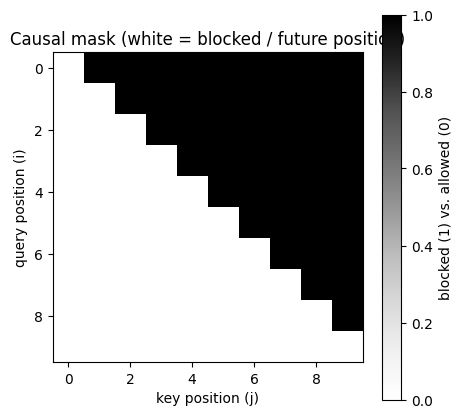

In [6]:
import matplotlib.pyplot as plt

T_demo = 10
mask_demo = build_causal_mask(T_demo).float().numpy()

plt.figure(figsize=(5, 5))
plt.imshow(mask_demo, cmap="Greys")
plt.title("Causal mask (white = blocked / future position)")
plt.xlabel("key position (j)")
plt.ylabel("query position (i)")
plt.colorbar(label="blocked (1) vs. allowed (0)")
plt.show()

**Milestone 1 checkpoint reached:** general self-attention with optional causal masking is implemented and passes shape + causal-correctness unit tests. Next: Milestone 2 (multi-head attention + positional encoding).

---
## Milestone 2 — Multi-Head Attention & Positional Encoding

Covers: multi-head attention with explicit split/merge (Lesson 03), sinusoidal positional encoding (Lesson 04).

In [7]:
class MultiHeadAttention(nn.Module):
    """Multi-head self-attention with explicit split/merge, built on top of
    the `scaled_dot_product_attention` function from Milestone 1.
    """

    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.causal = causal

        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)  # final projection after concat

    def split_heads(self, x):
        # (B, T, d_model) -> (B, n_heads, T, d_head)
        B, T, _ = x.shape
        x = x.view(B, T, self.n_heads, self.d_head)
        return x.transpose(1, 2)

    def merge_heads(self, x):
        # (B, n_heads, T, d_head) -> (B, T, d_model)
        B, n_heads, T, d_head = x.shape
        x = x.transpose(1, 2).contiguous()
        return x.view(B, T, n_heads * d_head)

    def forward(self, x, mask=None, verbose=False):
        B, T, _ = x.shape

        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        if verbose:
            print(f"[1] Q/K/V projected shape:        {tuple(Q.shape)}  (B, T, d_model)")

        Qh, Kh, Vh = self.split_heads(Q), self.split_heads(K), self.split_heads(V)
        if verbose:
            print(f"[2] after split_heads:             {tuple(Qh.shape)}  (B, n_heads, T, d_head)")

        # scaled_dot_product_attention broadcasts over the leading (B, n_heads) dims
        out_h, attn = scaled_dot_product_attention(Qh, Kh, Vh, mask=mask, causal=self.causal)
        if verbose:
            print(f"[3] per-head attention output:     {tuple(out_h.shape)}  (B, n_heads, T, d_head)")
            print(f"[3] per-head attention weights:    {tuple(attn.shape)}   (B, n_heads, T, T)")

        merged = self.merge_heads(out_h)
        if verbose:
            print(f"[4] after merge_heads (concat):    {tuple(merged.shape)}  (B, T, d_model)")

        out = self.W_o(merged)
        if verbose:
            print(f"[5] final projected output:        {tuple(out.shape)}  (B, T, d_model)")

        return out, attn

### 2.1 Figure 3 evidence — multi-head tensor-shape trace

Run with `verbose=True` to print the shape at every stage of split → per-head attention → merge → final projection. Screenshot this output for Section 12, Figure 3.

In [8]:
B, T, d_model, n_heads = 2, 12, 256, 8
mha = MultiHeadAttention(d_model=d_model, n_heads=n_heads, causal=True).to(DEVICE)
x_demo = torch.randn(B, T, d_model, device=DEVICE)

print(f"input shape:                       {tuple(x_demo.shape)}  (B, T, d_model)")
print(f"d_model={d_model}, n_heads={n_heads}, d_head={d_model // n_heads}\n")
out_demo, attn_demo = mha(x_demo, verbose=True)

input shape:                       (2, 12, 256)  (B, T, d_model)
d_model=256, n_heads=8, d_head=32

[1] Q/K/V projected shape:        (2, 12, 256)  (B, T, d_model)
[2] after split_heads:             (2, 8, 12, 32)  (B, n_heads, T, d_head)
[3] per-head attention output:     (2, 8, 12, 32)  (B, n_heads, T, d_head)
[3] per-head attention weights:    (2, 8, 12, 12)   (B, n_heads, T, T)
[4] after merge_heads (concat):    (2, 12, 256)  (B, T, d_model)
[5] final projected output:        (2, 12, 256)  (B, T, d_model)


### 2.2 Sinusoidal positional encoding

Injects order information into token embeddings using fixed (non-learned) sine/cosine functions of position, as in the original Transformer paper:

```
PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
```

In [9]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=1024):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)         # (max_len, 1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model)
        )  # (d_model/2,)

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, d_model), not a trainable param

    def forward(self, x):
        # x: (B, T, d_model)
        T = x.shape[1]
        return x + self.pe[:, :T, :]

### 2.3 Figure 4 evidence — positional encoding visualization

Two views: a heatmap of the encoding matrix (shows the characteristic sinusoidal banding across dimensions), and a line plot of a few individual dimensions across positions (shows different frequencies per dimension pair). Screenshot for Section 12, Figure 4.

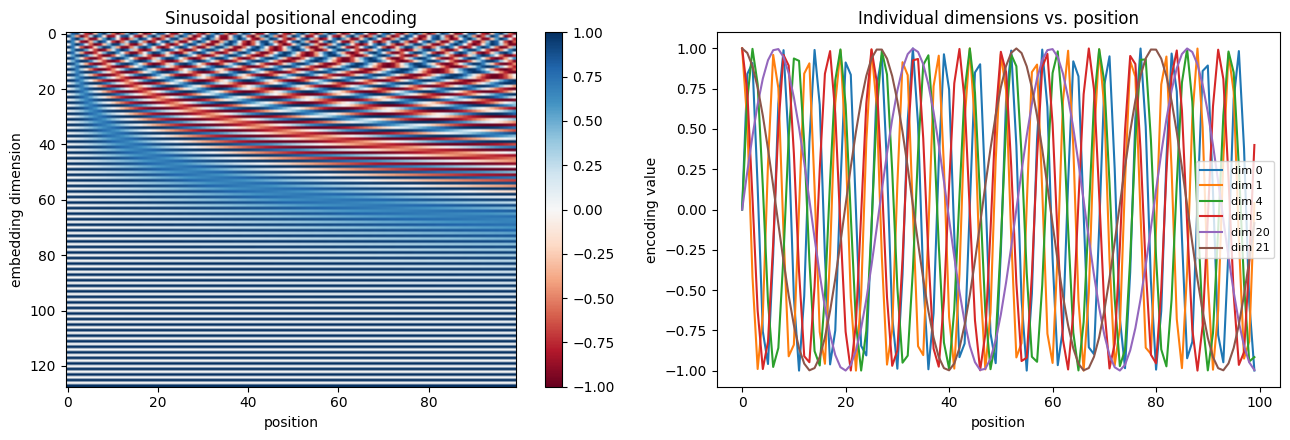

In [10]:
pos_enc = SinusoidalPositionalEncoding(d_model=128, max_len=100)
pe_matrix = pos_enc.pe[0].numpy()  # (100, 128)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

im = axes[0].imshow(pe_matrix.T, aspect="auto", cmap="RdBu")
axes[0].set_title("Sinusoidal positional encoding")
axes[0].set_xlabel("position")
axes[0].set_ylabel("embedding dimension")
fig.colorbar(im, ax=axes[0])

for dim in [0, 1, 4, 5, 20, 21]:
    axes[1].plot(pe_matrix[:, dim], label=f"dim {dim}")
axes[1].set_title("Individual dimensions vs. position")
axes[1].set_xlabel("position")
axes[1].set_ylabel("encoding value")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Interpretation:** each dimension pair `(2i, 2i+1)` oscillates at a different frequency, so every position gets a unique fixed vector, and the relative offset between any two positions is representable as a linear function of their encodings — this is how the model recovers order information despite attention itself being permutation-invariant.

### 2.4 Unit tests — multi-head shapes, causal correctness, positional encoding

In [11]:
def test_multihead_shapes():
    B, T, d_model, n_heads = 3, 9, 32, 4
    mha = MultiHeadAttention(d_model, n_heads, causal=False)
    x = torch.randn(B, T, d_model)
    out, attn = mha(x)
    assert out.shape == (B, T, d_model), f"unexpected output shape {out.shape}"
    assert attn.shape == (B, n_heads, T, T), f"unexpected attn shape {attn.shape}"


def test_multihead_requires_divisible_d_model():
    try:
        MultiHeadAttention(d_model=30, n_heads=8)
        raised = False
    except AssertionError:
        raised = True
    assert raised, "expected an assertion error for non-divisible d_model/n_heads"


def test_multihead_causal_mask_blocks_future():
    B, T, d_model, n_heads = 2, 8, 32, 4
    mha = MultiHeadAttention(d_model, n_heads, causal=True)
    x = torch.randn(B, T, d_model)
    _, attn = mha(x)  # (B, n_heads, T, T)
    causal_mask = build_causal_mask(T)  # True where j > i
    future_weights = attn[:, :, causal_mask]
    assert torch.allclose(future_weights, torch.zeros_like(future_weights), atol=1e-6), (
        "multi-head causal mask leaked attention to future positions"
    )


def test_positional_encoding_shape_and_variation():
    pe_module = SinusoidalPositionalEncoding(d_model=32, max_len=50)
    x = torch.zeros(2, 10, 32)
    out = pe_module(x)
    assert out.shape == (2, 10, 32)
    # different positions must receive different encodings
    assert not torch.allclose(out[:, 0, :], out[:, 1, :])
    # encoding must be deterministic / fixed (not trainable)
    assert not pe_module.pe.requires_grad


test_multihead_shapes()
test_multihead_requires_divisible_d_model()
test_multihead_causal_mask_blocks_future()
test_positional_encoding_shape_and_variation()
print("ALL TESTS PASSED")

ALL TESTS PASSED


**Milestone 2 checkpoint reached:** multi-head attention (explicit split/merge/project) and sinusoidal positional encoding are implemented and shape/causal-correctness verified. Next: Milestone 3 (full Transformer decoder block + MLM vs. CLM comparison).

---
## Milestone 3 — Transformer Block & CLM vs. MLM Objective Comparison

Covers: full Transformer decoder block — attention + FFN + residuals + normalization (Lesson 05), and why GPT's causal masking differs from BERT's bidirectional masking (Lesson 06).

In [12]:
class FeedForward(nn.Module):
    """Position-wise feed-forward network: two linear layers with a GELU
    nonlinearity in between, applied identically (with shared weights)
    to every position in the sequence.
    """

    def __init__(self, d_model, ffn_dim, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.GELU(),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

### 3.1 Transformer decoder block

Pre-norm residual design (LayerNorm applied *before* each sublayer, common in modern GPT-style models — more stable to train than the original post-norm formulation):

```
x = x + Attention(LayerNorm(x))
x = x + FeedForward(LayerNorm(x))
```

Both sublayers are wrapped in residual ("skip") connections, so gradients have a direct path through the network and each sublayer only has to learn a *residual update* to the representation rather than a full replacement of it.

In [13]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, dropout=0.0, causal=True):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, causal=causal)
        self.drop1 = nn.Dropout(dropout)

        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, ffn_dim, dropout=dropout)
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x, mask=None, verbose=False):
        # --- attention sublayer, pre-norm + residual ---
        attn_out, attn_weights = self.attn(self.ln1(x), mask=mask, verbose=verbose)
        x = x + self.drop1(attn_out)
        if verbose:
            print(f"after attention + residual:  {tuple(x.shape)}")

        # --- feed-forward sublayer, pre-norm + residual ---
        ffn_out = self.ffn(self.ln2(x))
        x = x + self.drop2(ffn_out)
        if verbose:
            print(f"after FFN + residual:        {tuple(x.shape)}")

        return x, attn_weights

**Block diagram** (for Section 4's architecture-diagram deliverable):

```
        x  (B, T, d_model)
        │
        ├────────────────────┐
        ▼                    │
     LayerNorm                │
        │                    │
  Multi-Head Attention        │  residual
   (causal mask)               │
        │                    │
        ▼                    │
       (+) ◄───────────────────┘
        │
        ├────────────────────┐
        ▼                    │
     LayerNorm                │
        │                    │
  Feed-Forward (GELU)         │  residual
        │                    │
        ▼                    │
       (+) ◄───────────────────┘
        │
        ▼
  output (B, T, d_model)
```

### 3.2 Figure 5 evidence — shape checks

Confirms the block preserves `(B, T, d_model)` end-to-end, which is required for stacking blocks in Milestone 5.

In [14]:
B, T, d_model, n_heads, ffn_dim = 2, 12, 256, 8, 4 * 256
block_demo = TransformerBlock(d_model, n_heads, ffn_dim, dropout=0.1, causal=True).to(DEVICE)
x_demo = torch.randn(B, T, d_model, device=DEVICE)

print(f"input shape:  {tuple(x_demo.shape)}")
out_demo, attn_demo = block_demo(x_demo, verbose=True)
print(f"\noutput shape: {tuple(out_demo.shape)}  (matches input -> block is stackable)")
assert out_demo.shape == x_demo.shape

input shape:  (2, 12, 256)
[1] Q/K/V projected shape:        (2, 12, 256)  (B, T, d_model)
[2] after split_heads:             (2, 8, 12, 32)  (B, n_heads, T, d_head)
[3] per-head attention output:     (2, 8, 12, 32)  (B, n_heads, T, d_head)
[3] per-head attention weights:    (2, 8, 12, 12)   (B, n_heads, T, T)
[4] after merge_heads (concat):    (2, 12, 256)  (B, T, d_model)
[5] final projected output:        (2, 12, 256)  (B, T, d_model)
after attention + residual:  (2, 12, 256)
after FFN + residual:        (2, 12, 256)

output shape: (2, 12, 256)  (matches input -> block is stackable)


### 3.3 GPT causal masking vs. BERT bidirectional masking (Lesson 06)

We are **not** building a full BERT model — only enough to demonstrate, with evidence, why the two objectives require different attention constraints:

- **GPT (causal / autoregressive):** each query position `i` may only attend to key positions `j <= i`. This is required because the training objective is *next-token prediction* — if position `i` could see position `i+1`, predicting token `i+1` from position `i` would be trivial (the answer would already be visible), so the model would learn nothing useful and generation (which only has past tokens available) would be impossible to replicate at inference time.
- **BERT (bidirectional / masked LM):** a query position may attend to **every** position in the sequence (subject only to a padding mask). This is possible because the training objective is different — some tokens are randomly replaced with a `[MASK]` token and the model predicts *those* from full left-and-right context. There is no "future leakage" problem because the target token itself is hidden from the input, not merely positioned later in the sequence.

#### Mask matrices (Figure evidence)

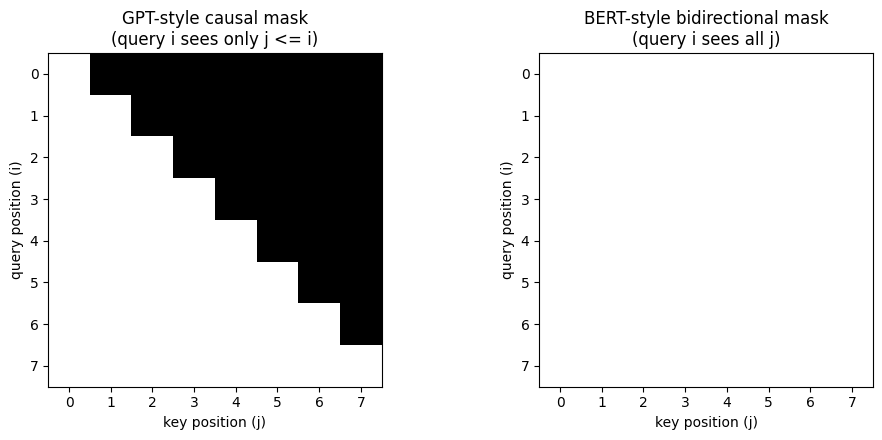

In [15]:
T_cmp = 8
causal_mask_cmp = build_causal_mask(T_cmp)                          # True = blocked
bidirectional_mask_cmp = torch.zeros(T_cmp, T_cmp, dtype=torch.bool)  # nothing blocked (ignoring padding)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].imshow(causal_mask_cmp.float(), cmap="Greys")
axes[0].set_title("GPT-style causal mask\n(query i sees only j <= i)")
axes[1].imshow(bidirectional_mask_cmp.float(), cmap="Greys")
axes[1].set_title("BERT-style bidirectional mask\n(query i sees all j)")
for ax in axes:
    ax.set_xlabel("key position (j)")
    ax.set_ylabel("query position (i)")
plt.tight_layout()
plt.show()

#### Short comparison experiment

We measure how much a `TransformerBlock`'s output at **position 0** changes when we perturb only the **last** (future-relative-to-position-0) token in the sequence. Under a correctly implemented causal mask, position 0's output must be mathematically unaffected by anything at a later position; under bidirectional attention, it should change.

In [16]:
def future_token_sensitivity(causal: bool, T=10, d_model=16, n_heads=4, trials=5, seed=0):
    """Average change in position-0's block output when the LAST token in the
    sequence is perturbed. Should be ~0 for causal attention, and clearly
    nonzero for bidirectional attention.
    """
    torch.manual_seed(seed)
    block = TransformerBlock(d_model, n_heads, ffn_dim=4 * d_model, dropout=0.0, causal=causal)
    block.eval()

    deltas = []
    for _ in range(trials):
        x = torch.randn(1, T, d_model)
        with torch.no_grad():
            out_a, _ = block(x)

        x_perturbed = x.clone()
        x_perturbed[:, -1, :] += torch.randn(d_model) * 5.0  # perturb only the last (future) token
        with torch.no_grad():
            out_b, _ = block(x_perturbed)

        delta = (out_a[:, 0, :] - out_b[:, 0, :]).norm().item()
        deltas.append(delta)
    return sum(deltas) / len(deltas)


causal_sensitivity = future_token_sensitivity(causal=True)
bidirectional_sensitivity = future_token_sensitivity(causal=False)

print(f"Causal (GPT-style):        avg change at position 0 = {causal_sensitivity:.8f}")
print(f"Bidirectional (BERT-style): avg change at position 0 = {bidirectional_sensitivity:.8f}")

Causal (GPT-style):        avg change at position 0 = 0.00000000
Bidirectional (BERT-style): avg change at position 0 = 0.22196493


**Observation (fill in exact numbers from your run):** the causal block's position-0 output changes by (numerically) zero when the last token is perturbed, while the bidirectional block's position-0 output changes substantially.

**Interpretation:** this confirms the causal mask is doing its job — no information from future positions leaks backward — which is exactly the property next-token prediction training requires and BERT-style masked prediction does not.

### 3.4 Unit tests — block shape, residual stacking, causal invariance

In [17]:
def test_transformer_block_preserves_shape():
    B, T, d_model, n_heads = 4, 10, 64, 4
    block = TransformerBlock(d_model, n_heads, ffn_dim=4 * d_model, causal=True)
    x = torch.randn(B, T, d_model)
    out, attn = block(x)
    assert out.shape == x.shape, f"block changed shape: {x.shape} -> {out.shape}"
    assert attn.shape == (B, n_heads, T, T)


def test_transformer_block_is_stackable():
    B, T, d_model, n_heads = 2, 8, 32, 4
    blocks = nn.ModuleList([
        TransformerBlock(d_model, n_heads, ffn_dim=4 * d_model, causal=True) for _ in range(4)
    ])
    x = torch.randn(B, T, d_model)
    for blk in blocks:
        x, _ = blk(x)
    assert x.shape == (B, T, d_model)


def test_causal_block_ignores_future_tokens():
    sensitivity = future_token_sensitivity(causal=True, trials=3)
    assert sensitivity < 1e-5, f"causal block leaked future information (delta={sensitivity})"


def test_bidirectional_block_uses_future_tokens():
    sensitivity = future_token_sensitivity(causal=False, trials=3)
    assert sensitivity > 1e-3, "bidirectional block unexpectedly ignored a perturbed future token"


test_transformer_block_preserves_shape()
test_transformer_block_is_stackable()
test_causal_block_ignores_future_tokens()
test_bidirectional_block_uses_future_tokens()
print("ALL TESTS PASSED")

ALL TESTS PASSED


**Milestone 3 checkpoint reached:** a complete, stackable Transformer decoder block (attention + FFN + residuals + LayerNorm) is implemented, and the causal-vs-bidirectional distinction is demonstrated with a mask-matrix figure and a measured invariance experiment. Next: Milestone 4 (GPT training pipeline — tokenizer, dataset, shifted targets, training loop).

---
## Milestone 4 — GPT Training Pipeline

Covers: character tokenizer, Tiny Shakespeare data pipeline, shifted next-token targets, the GPT model (assembled from the M1–M3 components), cross-entropy loss, autoregressive generation, a full training loop with logging/checkpointing, and the **tiny-overfit debugging gate**.

Nothing here loads a pretrained model — every weight is initialised from scratch.

In [18]:
import os
import random
import urllib.request
from dataclasses import dataclass, asdict

import numpy as np
from torch.utils.data import Dataset, DataLoader


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

### 4.1 Dataset — Tiny Shakespeare

Source: the Tiny Shakespeare corpus (~1.1 MB, ~40k lines), the same text as the Hugging Face *Tiny Shakespeare* dataset card; the raw file below is the original `char-rnn` release by Andrej Karpathy. **Cite this in the report.**

In [19]:
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_PATH = "data/tinyshakespeare.txt"

os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_PATH):
    print("Downloading Tiny Shakespeare ...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with open(DATA_PATH, "r", encoding="utf-8") as f:
    text = f.read()

print(f"characters: {len(text):,}")
print(f"lines:      {text.count(chr(10)):,}")
print("--- first 300 characters ---")
print(text[:300])

characters: 1,115,394
lines:      40,000
--- first 300 characters ---
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


### 4.2 Character-level tokenizer

**Vocabulary & special-token policy (document in the report):**
- Vocabulary = every distinct character in the corpus, sorted → fully deterministic.
- **No special tokens.** No padding (we always cut fixed-length windows), no BOS/EOS, no UNK.
- Encoding a character outside the vocabulary raises `KeyError` by default, or silently skips it with `errors="skip"` (used for free-form prompts at inference time).

In [20]:
class CharTokenizer:
    def __init__(self, chars):
        self.chars = list(chars)
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for i, c in enumerate(self.chars)}

    @classmethod
    def from_text(cls, text):
        return cls(sorted(set(text)))

    @property
    def vocab_size(self):
        return len(self.chars)

    def encode(self, s, errors="raise"):
        ids = []
        for c in s:
            if c in self.stoi:
                ids.append(self.stoi[c])
            elif errors == "skip":
                continue
            else:
                raise KeyError(f"character {c!r} is not in the vocabulary")
        return ids

    def decode(self, ids):
        return "".join(self.itos[int(i)] for i in ids)


tokenizer = CharTokenizer.from_text(text)
print(f"vocab_size = {tokenizer.vocab_size}")
print("vocabulary:", repr("".join(tokenizer.chars)))

sample = "First Citizen:"
enc = tokenizer.encode(sample)
print(f"\n{sample!r} -> {enc} -> {tokenizer.decode(enc)!r}")

vocab_size = 65
vocabulary: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"

'First Citizen:' -> [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10] -> 'First Citizen:'


### 4.3 Encoding, train/validation split, and the next-token dataset

- The whole corpus is encoded to one long tensor of token IDs.
- Split: first 90 % train, last 10 % validation (**contiguous**, not shuffled — otherwise validation windows would overlap training text).
- A `CharDataset` cuts **contiguous windows** of `context_length` tokens. For a window starting at `s`:

```
x = ids[s     : s + T]        # inputs
y = ids[s + 1 : s + T + 1]    # targets  (x shifted left by one)
```

so the target at position `t` is the token that follows input position `t`.

In [21]:
ids = torch.tensor(tokenizer.encode(text), dtype=torch.long)
n_train = int(0.9 * len(ids))
train_ids, val_ids = ids[:n_train], ids[n_train:]
print(f"total tokens: {len(ids):,} | train: {len(train_ids):,} | val: {len(val_ids):,}")


class CharDataset(Dataset):
    def __init__(self, ids, context_length, stride=1):
        self.ids = ids
        self.T = context_length
        self.stride = stride

    def __len__(self):
        return (len(self.ids) - self.T - 1) // self.stride + 1

    def __getitem__(self, i):
        s = i * self.stride
        x = self.ids[s : s + self.T]
        y = self.ids[s + 1 : s + self.T + 1]
        return x, y

    def get_batch(self, batch_size):
        """Random batch of (x, y), each of shape (B, T)."""
        starts = torch.randint(0, len(self), (batch_size,)) * self.stride
        x = torch.stack([self.ids[s : s + self.T] for s in starts])
        y = torch.stack([self.ids[s + 1 : s + self.T + 1] for s in starts])
        return x, y

total tokens: 1,115,394 | train: 1,003,854 | val: 111,540


#### Verify the target shift

In [22]:
demo_ds = CharDataset(train_ids, context_length=16)
x_s, y_s = demo_ds[0]

print(f"{'t':>2} | {'input token':>11} | {'target token':>12}")
print("-" * 32)
for t in range(10):
    print(f"{t:>2} | {tokenizer.decode([x_s[t]])!r:>11} | {tokenizer.decode([y_s[t]])!r:>12}")

# the target at position t must be the input at position t+1
assert torch.equal(x_s[1:], y_s[:-1])
print("\nshift check passed: y[t] == x[t+1]")

 t | input token | target token
--------------------------------
 0 |         'F' |          'i'
 1 |         'i' |          'r'
 2 |         'r' |          's'
 3 |         's' |          't'
 4 |         't' |          ' '
 5 |         ' ' |          'C'
 6 |         'C' |          'i'
 7 |         'i' |          't'
 8 |         't' |          'i'
 9 |         'i' |          'z'

shift check passed: y[t] == x[t+1]


### 4.4 Model configuration

In [23]:
@dataclass
class GPTConfig:
    vocab_size: int = 65
    context_length: int = 128
    d_model: int = 256
    n_heads: int = 4
    n_layers: int = 4
    ffn_dim: int = None        # defaults to 4 * d_model
    dropout: float = 0.1
    tie_weights: bool = False  # optional experiment: share token-embedding and LM-head weights

    def __post_init__(self):
        if self.ffn_dim is None:
            self.ffn_dim = 4 * self.d_model

### 4.5 The GPT model

```
token ids (B, T)
  -> token embedding (x sqrt(d_model))   (B, T, d_model)
  -> + sinusoidal positional encoding
  -> dropout
  -> N x TransformerBlock (causal)
  -> final LayerNorm
  -> LM head (Linear d_model -> vocab_size)   (B, T, vocab)
```

- Embeddings are scaled by `sqrt(d_model)` (as in the original Transformer) so the token signal is not drowned out by the unit-amplitude sinusoidal positions.
- Weights use `N(0, 0.02)` init; the residual-branch output projections (`W_o`, FFN second layer) are additionally scaled by `1/sqrt(2 * n_layers)` (GPT-2 style) to keep the residual stream variance stable with depth.
- **Loss:** token-level cross-entropy between logits `(B*T, vocab)` and shifted targets `(B*T,)`. At initialisation the loss should be close to `ln(vocab_size)`.

In [24]:
class GPT(nn.Module):
    def __init__(self, cfg: GPTConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos_enc = SinusoidalPositionalEncoding(cfg.d_model, max_len=cfg.context_length)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([
            TransformerBlock(cfg.d_model, cfg.n_heads, cfg.ffn_dim, cfg.dropout, causal=True)
            for _ in range(cfg.n_layers)
        ])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)

        if cfg.tie_weights:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("W_o.weight") or name.endswith("ffn.net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None, return_attn=False):
        B, T = idx.shape
        assert T <= self.cfg.context_length, f"sequence length {T} exceeds context_length {self.cfg.context_length}"

        x = self.tok_emb(idx) * math.sqrt(self.cfg.d_model)   # (B, T, d_model)
        x = self.drop(self.pos_enc(x))

        attn_maps = []
        for block in self.blocks:
            x, attn = block(x)
            if return_attn:
                attn_maps.append(attn)           # each: (B, n_heads, T, T)

        x = self.ln_f(x)
        logits = self.lm_head(x)                 # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))

        if return_attn:
            return logits, loss, attn_maps
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=None):
        """Autoregressive sampling. idx: (B, T0) token ids.
        temperature == 0 -> greedy decoding. top_k -> keep only the k most likely tokens.
        """
        was_training = self.training
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.context_length:]        # crop to the context window
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]                           # only the last position predicts the next token

            if temperature == 0:
                next_id = torch.argmax(logits, dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k is not None:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, [-1]]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                probs = F.softmax(logits, dim=-1)
                next_id = torch.multinomial(probs, num_samples=1)

            idx = torch.cat([idx, next_id], dim=1)
        self.train(was_training)
        return idx


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def generate_text(model, tokenizer, prompt, max_new_tokens=200, temperature=0.8, top_k=None):
    """Prompt string in -> prompt + continuation string out."""
    device = next(model.parameters()).device
    prompt_ids = tokenizer.encode(prompt, errors="skip") or tokenizer.encode("\n")
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens, temperature=temperature, top_k=top_k)
    return tokenizer.decode(out[0].tolist())

#### Sanity check: untrained model

Expect (a) logits of shape `(B, T, vocab_size)`, (b) initial loss ≈ `ln(vocab_size)` (the loss of a uniform guess), and (c) gibberish samples.

In [25]:
cfg_demo = GPTConfig(vocab_size=tokenizer.vocab_size, context_length=128, d_model=128, n_heads=4, n_layers=2, dropout=0.0)
model_demo = GPT(cfg_demo).to(DEVICE)

xb, yb = CharDataset(train_ids, cfg_demo.context_length).get_batch(8)
logits, loss = model_demo(xb.to(DEVICE), yb.to(DEVICE))

print(f"parameters:   {count_parameters(model_demo):,}")
print(f"logits shape: {tuple(logits.shape)}  (B, T, vocab_size)")
print(f"initial loss: {loss.item():.4f}   vs  ln(vocab_size) = {math.log(tokenizer.vocab_size):.4f}")
print("\n--- untrained sample ---")
print(generate_text(model_demo, tokenizer, "ROMEO:", max_new_tokens=100))

parameters:   412,416
logits shape: (8, 128, 65)  (B, T, vocab_size)
initial loss: 4.1769   vs  ln(vocab_size) = 4.1744

--- untrained sample ---
ROMEO:?qf;xbDkRZkNdc.wj,ZT,OLFT,eHtK
b:!PjCkMBbzA$3:.aSvgO-33jMBd?gLTa
hX:YVXJthXeNuwqcPMxG.tbVF dXl!DZaLe


### 4.6 Training utilities

- `TrainConfig` – all training hyper-parameters (configurable, as the handout requires).
- `get_lr` – linear warm-up then cosine decay to `min_lr`.
- `estimate_loss` – average loss over several batches in `eval` mode.
- `save_checkpoint` / `load_checkpoint` – the checkpoint stores weights, model config, **and the tokenizer vocabulary**, so a fresh process can rebuild everything and generate.
- `train` – AdamW (weight decay on matrices only), gradient clipping, and logging of **train loss, validation loss, learning rate, step, throughput, and periodic sample generations**.

In [26]:
@dataclass
class TrainConfig:
    max_steps: int = 2000
    batch_size: int = 64
    lr: float = 3e-4
    min_lr: float = 3e-5
    warmup_steps: int = 100
    weight_decay: float = 0.1
    grad_clip: float = 1.0
    eval_interval: int = 250
    eval_iters: int = 50
    log_interval: int = 50
    sample_max_new_tokens: int = 200
    sample_temperature: float = 0.8
    eval_at_start: bool = True
    seed: int = 1337


def get_lr(step, tcfg: TrainConfig):
    warmup = max(1, tcfg.warmup_steps)
    if step <= warmup:
        return tcfg.lr * step / warmup
    if step >= tcfg.max_steps:
        return tcfg.min_lr
    progress = (step - warmup) / (tcfg.max_steps - warmup)
    coeff = 0.5 * (1.0 + math.cos(math.pi * progress))
    return tcfg.min_lr + coeff * (tcfg.lr - tcfg.min_lr)


@torch.no_grad()
def estimate_loss(model, batch_fn, iters):
    was_training = model.training
    model.eval()
    losses = []
    for _ in range(iters):
        x, y = batch_fn()
        _, loss = model(x.to(DEVICE), y.to(DEVICE))
        losses.append(loss.item())
    model.train(was_training)
    return sum(losses) / len(losses)


def save_checkpoint(path, model, tokenizer, step=None, val_loss=None, tcfg=None):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    torch.save({
        "model_state": model.state_dict(),
        "gpt_config": asdict(model.cfg),
        "tokenizer_chars": tokenizer.chars,
        "step": step,
        "val_loss": val_loss,
        "train_config": asdict(tcfg) if tcfg is not None else None,
    }, path)


def load_checkpoint(path, device=DEVICE):
    ckpt = torch.load(path, map_location=device)
    model = GPT(GPTConfig(**ckpt["gpt_config"])).to(device)
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    tokenizer = CharTokenizer(ckpt["tokenizer_chars"])
    return model, tokenizer, ckpt

In [27]:
def train(model, train_batch_fn, val_batch_fn, tcfg: TrainConfig,
          tokenizer=None, sample_prompt="ROMEO:", ckpt_path=None, verbose=True):
    """Generic training loop.
    train_batch_fn / val_batch_fn: zero-argument callables returning an (x, y) batch.
    ckpt_path: if given, the checkpoint with the best validation loss is saved there.
    Returns a history dict (used for the loss curves and the ablations).
    """
    set_seed(tcfg.seed)
    model.to(DEVICE)

    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    optimizer = torch.optim.AdamW(
        [{"params": decay, "weight_decay": tcfg.weight_decay},
         {"params": no_decay, "weight_decay": 0.0}],
        lr=tcfg.lr, betas=(0.9, 0.95),
    )

    hist = {"log_step": [], "train_loss": [], "lr": [],
            "eval_step": [], "val_loss": [], "samples": []}
    best_val = float("inf")
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    def do_eval(step):
        nonlocal best_val
        val_loss = estimate_loss(model, val_batch_fn, tcfg.eval_iters)
        hist["eval_step"].append(step)
        hist["val_loss"].append(val_loss)
        improved = val_loss < best_val
        if improved:
            best_val = val_loss
            if ckpt_path:
                save_checkpoint(ckpt_path, model, tokenizer, step=step, val_loss=val_loss, tcfg=tcfg)
        if verbose:
            print(f"  >> eval @ step {step}: val_loss {val_loss:.4f} | val_ppl {math.exp(val_loss):.2f}"
                  + (" | saved best" if (improved and ckpt_path) else ""))
        if tokenizer is not None:
            s = generate_text(model, tokenizer, sample_prompt,
                              max_new_tokens=tcfg.sample_max_new_tokens,
                              temperature=tcfg.sample_temperature)
            hist["samples"].append((step, s))
            if verbose:
                print("  --- sample ---")
                print("  " + s.replace("\n", "\n  "))
                print("  --------------")

    if tcfg.eval_at_start:
        do_eval(0)

    model.train()
    t0 = time.time()
    running, count = 0.0, 0
    tokens_seen = 0
    for step in range(1, tcfg.max_steps + 1):
        lr = get_lr(step, tcfg)
        for g in optimizer.param_groups:
            g["lr"] = lr

        x, y = train_batch_fn()
        x, y = x.to(DEVICE), y.to(DEVICE)
        _, loss = model(x, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        if tcfg.grad_clip:
            torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg.grad_clip)
        optimizer.step()

        running += loss.item()
        count += 1
        tokens_seen += x.numel()

        if step % tcfg.log_interval == 0:
            avg = running / count
            hist["log_step"].append(step)
            hist["train_loss"].append(avg)
            hist["lr"].append(lr)
            if verbose:
                tps = tokens_seen / (time.time() - t0)
                print(f"step {step:5d}/{tcfg.max_steps} | train_loss {avg:.4f} | lr {lr:.2e} | {tps:,.0f} tok/s")
            running, count = 0.0, 0

        if step % tcfg.eval_interval == 0 or step == tcfg.max_steps:
            do_eval(step)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    hist["train_time_s"] = time.time() - t0
    hist["tokens_per_s"] = tokens_seen / hist["train_time_s"]
    hist["peak_mem_mb"] = torch.cuda.max_memory_allocated() / 2**20 if DEVICE.type == "cuda" else None
    hist["best_val_loss"] = best_val
    hist["final_val_loss"] = hist["val_loss"][-1]
    hist["final_train_loss"] = hist["train_loss"][-1] if hist["train_loss"] else None
    return hist


def plot_history(hist, title="Training curves"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist["log_step"], hist["train_loss"], label="train loss")
    axes[0].plot(hist["eval_step"], hist["val_loss"], "o-", label="validation loss")
    axes[0].set_xlabel("step")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_title(title)
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(hist["log_step"], hist["lr"])
    axes[1].set_xlabel("step")
    axes[1].set_ylabel("learning rate")
    axes[1].set_title("Learning-rate schedule (warm-up + cosine)")
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

### 4.7 Debugging gate — tiny overfit test

Before any long training, the model must be able to **memorise one small repeated batch**. If the loss cannot be driven far below its starting value (`≈ ln(vocab)`), something is broken (target shift, masking, gradients, optimiser, …). The gate below trains a small model on a single fixed batch of 8 windows and requires the loss to fall substantially.

  >> eval @ step 0: val_loss 4.2056 | val_ppl 67.06
step    25/300 | train_loss 3.6037 | lr 3.00e-03 | 38,074 tok/s
step    50/300 | train_loss 2.3438 | lr 2.92e-03 | 50,184 tok/s
step    75/300 | train_loss 1.2219 | lr 2.75e-03 | 57,079 tok/s
step   100/300 | train_loss 0.2490 | lr 2.49e-03 | 60,621 tok/s
  >> eval @ step 100: val_loss 0.0416 | val_ppl 1.04
step   125/300 | train_loss 0.0162 | lr 2.17e-03 | 63,309 tok/s
step   150/300 | train_loss 0.0036 | lr 1.80e-03 | 65,839 tok/s
step   175/300 | train_loss 0.0018 | lr 1.42e-03 | 67,639 tok/s
step   200/300 | train_loss 0.0011 | lr 1.06e-03 | 69,138 tok/s
  >> eval @ step 200: val_loss 0.0009 | val_ppl 1.00
step   225/300 | train_loss 0.0007 | lr 7.50e-04 | 70,012 tok/s
step   250/300 | train_loss 0.0005 | lr 5.07e-04 | 70,507 tok/s
step   275/300 | train_loss 0.0004 | lr 3.53e-04 | 71,171 tok/s
step   300/300 | train_loss 0.0003 | lr 3.00e-04 | 71,947 tok/s
  >> eval @ step 300: val_loss 0.0002 | val_ppl 1.00

initial loss: 4.2056

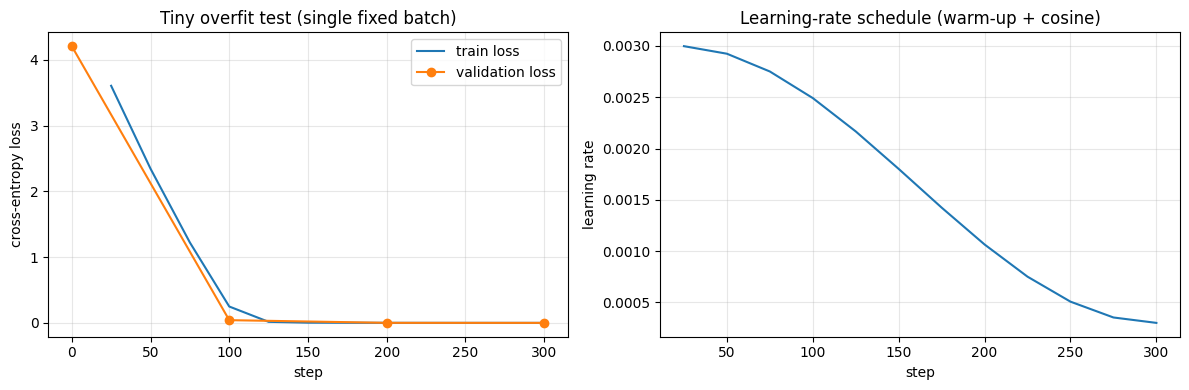

In [28]:
overfit_cfg = GPTConfig(vocab_size=tokenizer.vocab_size, context_length=64,
                        d_model=64, n_heads=4, n_layers=2, dropout=0.0)
set_seed(SEED)
overfit_model = GPT(overfit_cfg)

x_fix, y_fix = CharDataset(train_ids, overfit_cfg.context_length).get_batch(8)
fixed_batch_fn = lambda: (x_fix, y_fix)          # the same batch every step

overfit_tcfg = TrainConfig(max_steps=300, batch_size=8, lr=3e-3, min_lr=3e-4, warmup_steps=20,
                           weight_decay=0.0, eval_interval=100, eval_iters=1, log_interval=25)

overfit_hist = train(overfit_model, fixed_batch_fn, fixed_batch_fn, overfit_tcfg, tokenizer=None)

initial_loss, final_loss = overfit_hist["val_loss"][0], overfit_hist["val_loss"][-1]
print(f"\ninitial loss: {initial_loss:.4f}  ->  final loss: {final_loss:.4f}")
assert final_loss < 0.25 * initial_loss, "OVERFIT GATE FAILED: loss did not fall substantially"
print("OVERFIT GATE PASSED: gradients, target shifting, and masking are working")
plot_history(overfit_hist, title="Tiny overfit test (single fixed batch)")

### 4.8 Unit tests — tokenizer, dataset, GPT, causality, checkpoint round-trip

In [29]:
def test_tokenizer_roundtrip():
    s = "To be, or not to be: that is the question."
    assert tokenizer.decode(tokenizer.encode(s)) == s
    assert tokenizer.encode("a\u2603b", errors="skip") == tokenizer.encode("ab")
    try:
        tokenizer.encode("\u2603")
        raised = False
    except KeyError:
        raised = True
    assert raised


def test_dataset_target_shift():
    ds = CharDataset(train_ids, context_length=32)
    for i in [0, 1, 1000, len(ds) - 1]:
        x, y = ds[i]
        assert x.shape == (32,) and y.shape == (32,)
        assert torch.equal(x[1:], y[:-1])            # y[t] == x[t+1]
        assert y[-1] == train_ids[i + 32]            # last target is the true next token
    xb, yb = ds.get_batch(5)
    assert xb.shape == (5, 32) and yb.shape == (5, 32)


def test_gpt_forward_shapes_and_initial_loss():
    cfg = GPTConfig(vocab_size=tokenizer.vocab_size, context_length=32, d_model=32, n_heads=4, n_layers=2, dropout=0.0)
    model = GPT(cfg)
    x, y = CharDataset(train_ids, 32).get_batch(4)
    logits, loss = model(x, y)
    assert logits.shape == (4, 32, tokenizer.vocab_size)
    assert abs(loss.item() - math.log(tokenizer.vocab_size)) < 0.5


def test_gpt_is_causal_end_to_end():
    cfg = GPTConfig(vocab_size=tokenizer.vocab_size, context_length=32, d_model=32, n_heads=4, n_layers=3, dropout=0.0)
    model = GPT(cfg).eval()
    x = torch.randint(0, tokenizer.vocab_size, (1, 32))
    x2 = x.clone()
    x2[:, -1] = (x2[:, -1] + 1) % tokenizer.vocab_size       # change only the LAST token
    with torch.no_grad():
        l1, _ = model(x)
        l2, _ = model(x2)
    assert torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-5), "earlier positions changed -> future leakage!"
    assert not torch.allclose(l1[:, -1], l2[:, -1], atol=1e-5)  # sanity: the last position does change


def test_generation_length_and_greedy_determinism():
    cfg = GPTConfig(vocab_size=tokenizer.vocab_size, context_length=16, d_model=32, n_heads=4, n_layers=2, dropout=0.0)
    model = GPT(cfg)
    prompt = torch.tensor([tokenizer.encode("ROMEO:")])
    out1 = model.generate(prompt, max_new_tokens=40, temperature=0)   # longer than context -> exercises cropping
    out2 = model.generate(prompt, max_new_tokens=40, temperature=0)
    assert out1.shape == (1, prompt.shape[1] + 40)
    assert torch.equal(out1, out2)


def test_checkpoint_roundtrip(tmp_path="checkpoints/_test_ckpt.pt"):
    cfg = GPTConfig(vocab_size=tokenizer.vocab_size, context_length=16, d_model=32, n_heads=4, n_layers=2, dropout=0.0)
    model = GPT(cfg)
    save_checkpoint(tmp_path, model, tokenizer, step=1, val_loss=1.23)
    model2, tok2, ckpt = load_checkpoint(tmp_path, device=torch.device("cpu"))
    assert tok2.chars == tokenizer.chars
    prompt = torch.tensor([tokenizer.encode("ROMEO:")])
    a = model.cpu().generate(prompt, 20, temperature=0)
    b = model2.generate(prompt, 20, temperature=0)
    assert torch.equal(a, b)
    os.remove(tmp_path)


test_tokenizer_roundtrip()
test_dataset_target_shift()
test_gpt_forward_shapes_and_initial_loss()
test_gpt_is_causal_end_to_end()
test_generation_length_and_greedy_determinism()
test_checkpoint_roundtrip()
model_demo.to(DEVICE)
print("ALL TESTS PASSED")

ALL TESTS PASSED


**Milestone 4 checkpoint reached:** the full pipeline — tokenizer → shifted-target dataset → causal GPT → cross-entropy → training loop with logging/checkpointing — works, and the tiny-overfit gate confirms the loss can be driven down on a repeated batch. Next: Milestone 5 (train MiniGPT on the full dataset, record parameter count / config / hardware / time, and generate five fixed-prompt samples).

---
## Milestone 5 — MiniGPT: Full Training, Samples & Attention Inspection

Covers: training the compact GPT on the full Tiny Shakespeare corpus and recording everything the handout asks for — **parameter count, training configuration, hardware, wall-clock time, final train/validation loss, and fixed-prompt generation samples** — plus a first look at what the trained attention heads actually do (Figure 7).

> Use a **GPU runtime** in Colab (`Runtime > Change runtime type > GPU`). Edit the config cell below if your hardware needs a smaller model, and document any change in the report.

### 5.1 Hardware & environment (record in the report)

In [30]:
import json
import platform

hardware = {
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "gpu_memory_gb": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1) if torch.cuda.is_available() else None,
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "python": platform.python_version(),
    "platform": platform.platform(),
    "cpu_count": os.cpu_count(),
}
for k, v in hardware.items():
    print(f"{k:>14}: {v}")

for d in ["outputs/figures", "outputs/logs", "outputs/samples", "checkpoints"]:
    os.makedirs(d, exist_ok=True)

        device: cuda
           gpu: Tesla T4
 gpu_memory_gb: 14.6
         torch: 2.11.0+cu130
          cuda: 13.0
        python: 3.13.15
      platform: Linux-6.6.122+-x86_64-with-glibc2.39
     cpu_count: 2


### 5.2 Configuration

Starting recommendation from the handout (`d_model=256`, `n_heads=4`, `n_layers=4`, `ffn_dim=4*d_model`, `context_length=128`, AdamW, lr around `3e-4`, dropout 0.0-0.1), landing at roughly 3.2 M parameters.

Choices to justify in the report:
- **Dropout 0.1:** Tiny Shakespeare is only ~1 M characters, so the model sees each character many times; dropout slows overfitting.
- **Learning rate 6e-4 with warm-up + cosine decay:** a small model tolerates a higher rate than the 3e-4 starting point; tune if the loss curve is unstable.
- **3000 steps x 64 x 128 tokens ≈ 24.6 M tokens ≈ 24 epochs.** Validation loss is monitored throughout and the **best-validation checkpoint** is the one kept, so any late overfitting is visible in the curve but does not hurt the final model.

In [31]:
model_cfg = GPTConfig(
    vocab_size=tokenizer.vocab_size,
    context_length=128,
    d_model=256,
    n_heads=4,
    n_layers=4,
    ffn_dim=4 * 256,
    dropout=0.1,
    tie_weights=False,
)

train_cfg = TrainConfig(
    max_steps=3000,
    batch_size=64,
    lr=6e-4,
    min_lr=6e-5,
    warmup_steps=200,
    weight_decay=0.1,
    grad_clip=1.0,
    eval_interval=250,
    eval_iters=50,
    log_interval=50,
    sample_max_new_tokens=200,
    sample_temperature=0.8,
    seed=1337,
)

CKPT_BEST = "checkpoints/minigpt_best.pt"
CKPT_LAST = "checkpoints/minigpt_last.pt"

print("MODEL CONFIG:", asdict(model_cfg))
print("TRAIN CONFIG:", asdict(train_cfg))

MODEL CONFIG: {'vocab_size': 65, 'context_length': 128, 'd_model': 256, 'n_heads': 4, 'n_layers': 4, 'ffn_dim': 1024, 'dropout': 0.1, 'tie_weights': False}
TRAIN CONFIG: {'max_steps': 3000, 'batch_size': 64, 'lr': 0.0006, 'min_lr': 6e-05, 'warmup_steps': 200, 'weight_decay': 0.1, 'grad_clip': 1.0, 'eval_interval': 250, 'eval_iters': 50, 'log_interval': 50, 'sample_max_new_tokens': 200, 'sample_temperature': 0.8, 'eval_at_start': True, 'seed': 1337}


### 5.3 Figure 5 evidence — model summary & parameter count

A per-component breakdown whose rows add up exactly to the total (asserted), so the architecture and scale are unambiguous.

In [32]:
def model_summary(model):
    cfg = model.cfg
    n = lambda m: sum(p.numel() for p in m.parameters())
    blk = model.blocks[0]
    tied = cfg.tie_weights

    rows = [
        ("token embedding", tuple(model.tok_emb.weight.shape), n(model.tok_emb)),
        ("positional encoding (fixed, not trained)", tuple(model.pos_enc.pe.shape[1:]), 0),
        ("  per block: multi-head attention (Wq,Wk,Wv,Wo)", f"4 x ({cfg.d_model}x{cfg.d_model})", n(blk.attn)),
        ("  per block: feed-forward (GELU MLP)", f"{cfg.d_model}->{cfg.ffn_dim}->{cfg.d_model}", n(blk.ffn)),
        ("  per block: 2 x LayerNorm", f"2 x {cfg.d_model}", n(blk.ln1) + n(blk.ln2)),
    ]
    blocks_total = n(model.blocks)
    summary_total = [
        (f"all {cfg.n_layers} transformer blocks", "", blocks_total),
        ("final LayerNorm", (cfg.d_model,), n(model.ln_f)),
        ("LM head" + (" (tied to embedding, counted once)" if tied else ""),
         (cfg.d_model, cfg.vocab_size), 0 if tied else n(model.lm_head)),
    ]

    print(f"{'component':<52}{'shape':<26}{'params':>12}")
    print("-" * 90)
    for name, shape, p in rows:
        print(f"{name:<52}{str(shape):<26}{p:>12,}")
    for name, shape, p in summary_total:
        print(f"{name:<52}{str(shape):<26}{p:>12,}")
    print("-" * 90)

    total = count_parameters(model)
    parts = n(model.tok_emb) + blocks_total + n(model.ln_f) + (0 if tied else n(model.lm_head))
    assert parts == total, f"breakdown ({parts:,}) does not match total ({total:,})"
    print(f"{'TOTAL trainable parameters':<78}{total:>12,}  (~{total / 1e6:.2f}M)")
    print(f"{'fp32 weight size':<78}{total * 4 / 2**20:>10.1f} MB")
    print(f"\nvocab_size={cfg.vocab_size} | context_length={cfg.context_length} | d_model={cfg.d_model} | "
          f"n_heads={cfg.n_heads} (d_head={cfg.d_model // cfg.n_heads}) | n_layers={cfg.n_layers} | "
          f"ffn_dim={cfg.ffn_dim} | dropout={cfg.dropout}")
    return total


set_seed(train_cfg.seed)
model = GPT(model_cfg).to(DEVICE)
n_params = model_summary(model)
print()
print(model)

component                                           shape                           params
------------------------------------------------------------------------------------------
token embedding                                     (65, 256)                       16,640
positional encoding (fixed, not trained)            (128, 256)                           0
  per block: multi-head attention (Wq,Wk,Wv,Wo)     4 x (256x256)                  262,144
  per block: feed-forward (GELU MLP)                256->1024->256                 525,568
  per block: 2 x LayerNorm                          2 x 256                          1,024
all 4 transformer blocks                                                         3,154,944
final LayerNorm                                     (256,)                             512
LM head                                             (256, 65)                       16,640
------------------------------------------------------------------------------------------

### 5.4 Train MiniGPT

Trains on the **full** training split (90 %), validating on the held-out 10 % every `eval_interval` steps. Every evaluation also prints a sample from the prompt `ROMEO:`, so you can watch the text improve from noise to Shakespeare-shaped output. The best-validation checkpoint is written to `checkpoints/minigpt_best.pt`.

In [33]:
train_ds = CharDataset(train_ids, model_cfg.context_length)
val_ds = CharDataset(val_ids, model_cfg.context_length)

train_batch_fn = lambda: train_ds.get_batch(train_cfg.batch_size)
val_batch_fn = lambda: val_ds.get_batch(train_cfg.batch_size)

hist = train(model, train_batch_fn, val_batch_fn, train_cfg,
             tokenizer=tokenizer, sample_prompt="ROMEO:", ckpt_path=CKPT_BEST)

save_checkpoint(CKPT_LAST, model, tokenizer, step=train_cfg.max_steps, val_loss=hist["final_val_loss"], tcfg=train_cfg)
print(f"\nwall-clock training time: {hist['train_time_s']:.1f} s ({hist['train_time_s'] / 60:.1f} min)")
print(f"throughput: {hist['tokens_per_s']:,.0f} tokens/s | peak GPU memory: {hist['peak_mem_mb']}")

  >> eval @ step 0: val_loss 4.2384 | val_ppl 69.30 | saved best
  --- sample ---
  ROMEO:?qfzxBDkRZkNdc.wj,ZT,OLFT,eHtK
  b:iPjCkMBbzA$3:XaSvgO-3FjMBF?gLTauhX:YVXHtQXfzuwqcBMxG.tbVF dXlzDZaLeHFw3cHPDRWf,fDEZnYzxzoWoWX
  Yo3&$LMtofViEIvB!!&V!$W;Kd!lWZ,ueg ixYeYEYngciK;lxW;HFGEZroG EtSXUB;qWk G
  --------------
step    50/3000 | train_loss 3.6889 | lr 1.50e-04 | 128,269 tok/s
step   100/3000 | train_loss 2.8364 | lr 3.00e-04 | 128,202 tok/s
step   150/3000 | train_loss 2.5292 | lr 4.50e-04 | 127,729 tok/s
step   200/3000 | train_loss 2.3909 | lr 6.00e-04 | 127,365 tok/s
step   250/3000 | train_loss 2.2853 | lr 6.00e-04 | 127,022 tok/s
  >> eval @ step 250: val_loss 2.2422 | val_ppl 9.41 | saved best
  --- sample ---
  ROMEO:
  O urst inTh peth and qut aull--thele the wins cond by tharee wee
  Mes thand Coughar naik your kend,
  The landl wind and.
  
  Frourst I whak a winges heners theace andst bend
  The Ind andd yhay thangh plorr
  --------------
step   300/3000 | train_loss 2.2132 |

### 5.5 Final metrics (best checkpoint, deterministic evaluation)

The running training loss logged during training is computed **with dropout active** on random batches, so it is not directly comparable to validation loss. For the final numbers we reload the best checkpoint and score **both splits the same way**: eval mode, non-overlapping windows covering the entire split. Perplexity is `exp(loss)`; bits-per-character is `loss / ln 2`.

In [34]:
@torch.no_grad()
def full_split_loss(model, split_ids, context_length, batch_size=64):
    """Deterministic loss over an entire split using non-overlapping windows (eval mode)."""
    model.eval()
    T = context_length
    n_windows = (len(split_ids) - 1) // T
    total, count = 0.0, 0
    for i in range(0, n_windows, batch_size):
        starts = [j * T for j in range(i, min(i + batch_size, n_windows))]
        x = torch.stack([split_ids[s : s + T] for s in starts]).to(DEVICE)
        y = torch.stack([split_ids[s + 1 : s + T + 1] for s in starts]).to(DEVICE)
        _, loss = model(x, y)
        total += loss.item() * x.numel()
        count += x.numel()
    return total / count


best_model, _, best_ckpt = load_checkpoint(CKPT_BEST)

final_train_loss = full_split_loss(best_model, train_ids, model_cfg.context_length)
final_val_loss = full_split_loss(best_model, val_ids, model_cfg.context_length)
best_step = best_ckpt["step"]

results = {
    "parameters": n_params,
    "best_step": best_step,
    "final_train_loss": final_train_loss,
    "final_val_loss": final_val_loss,
    "train_perplexity": math.exp(final_train_loss),
    "val_perplexity": math.exp(final_val_loss),
    "val_bits_per_char": final_val_loss / math.log(2),
    "last_step_val_loss": hist["final_val_loss"],
    "train_time_s": hist["train_time_s"],
    "tokens_per_s": hist["tokens_per_s"],
    "peak_mem_mb": hist["peak_mem_mb"],
}

print(f"{'parameters':<28}{n_params:>14,}")
print(f"{'best checkpoint at step':<28}{best_step:>14}")
print(f"{'final TRAIN loss (eval mode)':<28}{final_train_loss:>14.4f}   ppl {math.exp(final_train_loss):.3f}")
print(f"{'final VAL loss':<28}{final_val_loss:>14.4f}   ppl {math.exp(final_val_loss):.3f}   ({final_val_loss / math.log(2):.3f} bits/char)")
print(f"{'val loss at last step':<28}{hist['final_val_loss']:>14.4f}")
print(f"{'train-val gap':<28}{final_val_loss - final_train_loss:>14.4f}")
print(f"{'wall-clock time':<28}{hist['train_time_s'] / 60:>13.1f}m")
print(f"{'uniform-guess baseline':<28}{math.log(tokenizer.vocab_size):>14.4f}   ppl {tokenizer.vocab_size}")

parameters                       3,188,736
best checkpoint at step               2750
final TRAIN loss (eval mode)        1.3020   ppl 3.677
final VAL loss                      1.5382   ppl 4.656   (2.219 bits/char)
val loss at last step               1.5426
train-val gap                       0.2362
wall-clock time                       3.9m
uniform-guess baseline              4.1744   ppl 65


### 5.6 Figure 6 evidence — training vs. validation loss

**Observation vs. interpretation for the report:** read off where validation loss bottoms out and whether it turns upward afterwards (observation); a rising validation loss while training loss keeps falling indicates overfitting to the small corpus (interpretation, supported by the train-val gap above). Note the logged training curve is measured with dropout on, so it can sit *above* validation loss early in training.

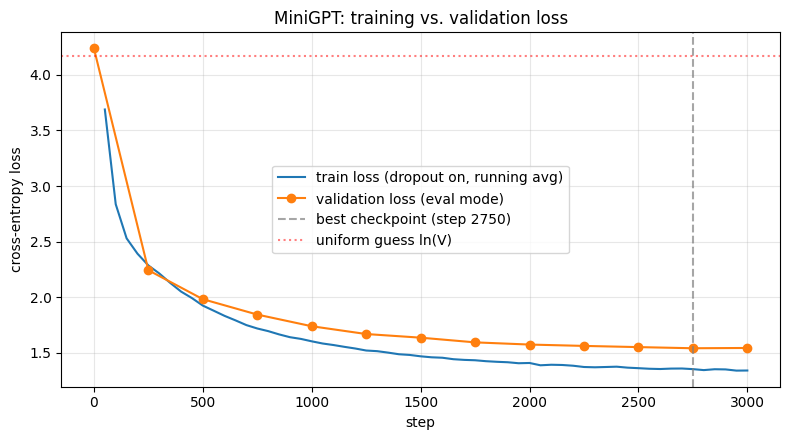

In [35]:
def plot_loss_curves(hist, best_step=None, path=None, title="MiniGPT: training vs. validation loss"):
    plt.figure(figsize=(8, 4.5))
    plt.plot(hist["log_step"], hist["train_loss"], label="train loss (dropout on, running avg)")
    plt.plot(hist["eval_step"], hist["val_loss"], "o-", label="validation loss (eval mode)")
    if best_step is not None:
        plt.axvline(best_step, color="gray", linestyle="--", alpha=0.7, label=f"best checkpoint (step {best_step})")
    plt.axhline(math.log(tokenizer.vocab_size), color="red", linestyle=":", alpha=0.5, label="uniform guess ln(V)")
    plt.xlabel("step")
    plt.ylabel("cross-entropy loss")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    if path:
        plt.savefig(path, dpi=150)
    plt.show()


plot_loss_curves(hist, best_step=best_step, path="outputs/figures/fig6_loss_curves.png")

### 5.7 Figure 8 evidence — generation from fixed prompts

Six fixed prompts (five in-domain plus one deliberately out-of-domain probe), temperature 0.8, a fixed seed before **each** prompt so the samples are reproducible. Samples come from the best checkpoint and are saved to `outputs/samples/`.

In [36]:
FIXED_PROMPTS = [
    "ROMEO:",
    "First Citizen:\n",
    "To be, or not to be",
    "The king",
    "JULIET:\n",
    "The future of artificial intelligence",   # out-of-domain probe
]
GEN_TEMPERATURE = 0.8
GEN_MAX_NEW_TOKENS = 300

sample_lines = [f"model: MiniGPT ({n_params:,} params) | checkpoint step {best_step} | "
                f"temperature {GEN_TEMPERATURE} | max_new_tokens {GEN_MAX_NEW_TOKENS} | seed per prompt: {SEED}\n"]
for i, prompt in enumerate(FIXED_PROMPTS, 1):
    set_seed(SEED)
    out = generate_text(best_model, tokenizer, prompt, max_new_tokens=GEN_MAX_NEW_TOKENS, temperature=GEN_TEMPERATURE)
    block = f"===== Sample {i} | prompt: {prompt!r} =====\n{out}\n"
    print(block)
    sample_lines.append(block)

with open("outputs/samples/fixed_prompt_samples.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(sample_lines))
print("saved -> outputs/samples/fixed_prompt_samples.txt")

===== Sample 1 | prompt: 'ROMEO:' =====
ROMEO:
All thy bride will be on, but
being about to take and my cold and bardity;
Nurse, by that did how enjoy the confessary,
And he owes more in her to sleep;
Which in tell their ladies in the sea,
Which now thou art self and peace the mild have
A children her years in a kingdom of the house.

JULIET:
I

===== Sample 2 | prompt: 'First Citizen:\n' =====
First Citizen:
What is the devil, which you that you bear to take
On the cast and bard thee us of his back:
And affection my father, will must be some
for the covertant to cause the senator;
Still in the speak of love, on that speaks no mean.
How may child at your son, why now?

POMPEY:
I think you may let my that

===== Sample 3 | prompt: 'To be, or not to be' =====
To be, or not to be some scorn'd of a worse
To threaten a way and answer'd the gate
My arm that unquest but we than a full of more,
Than when my father's of in her to stand;
Which in tears his that Hercutes to the queen.

DUKE VINCE

### 5.8 Figure 7 evidence — attention inspection on the trained model

Two views of the real attention weights from the trained model on a snippet of **validation** text:

1. **Grid of every head in every layer** — each panel is a `(T x T)` matrix (row = query position, column = key position). Every panel must be lower-triangular (the causal mask).
2. **One head with character labels** — so you can read which earlier characters a position attends to.

A small table also reports two simple, measurable head statistics: the mean attention on the **previous token** and on **itself**. Use these as *observations*; any claim about what a head "does" is an *interpretation* that needs this kind of evidence behind it.

snippet: 'd mild behavior,\nAm bold to show myself a forwar'


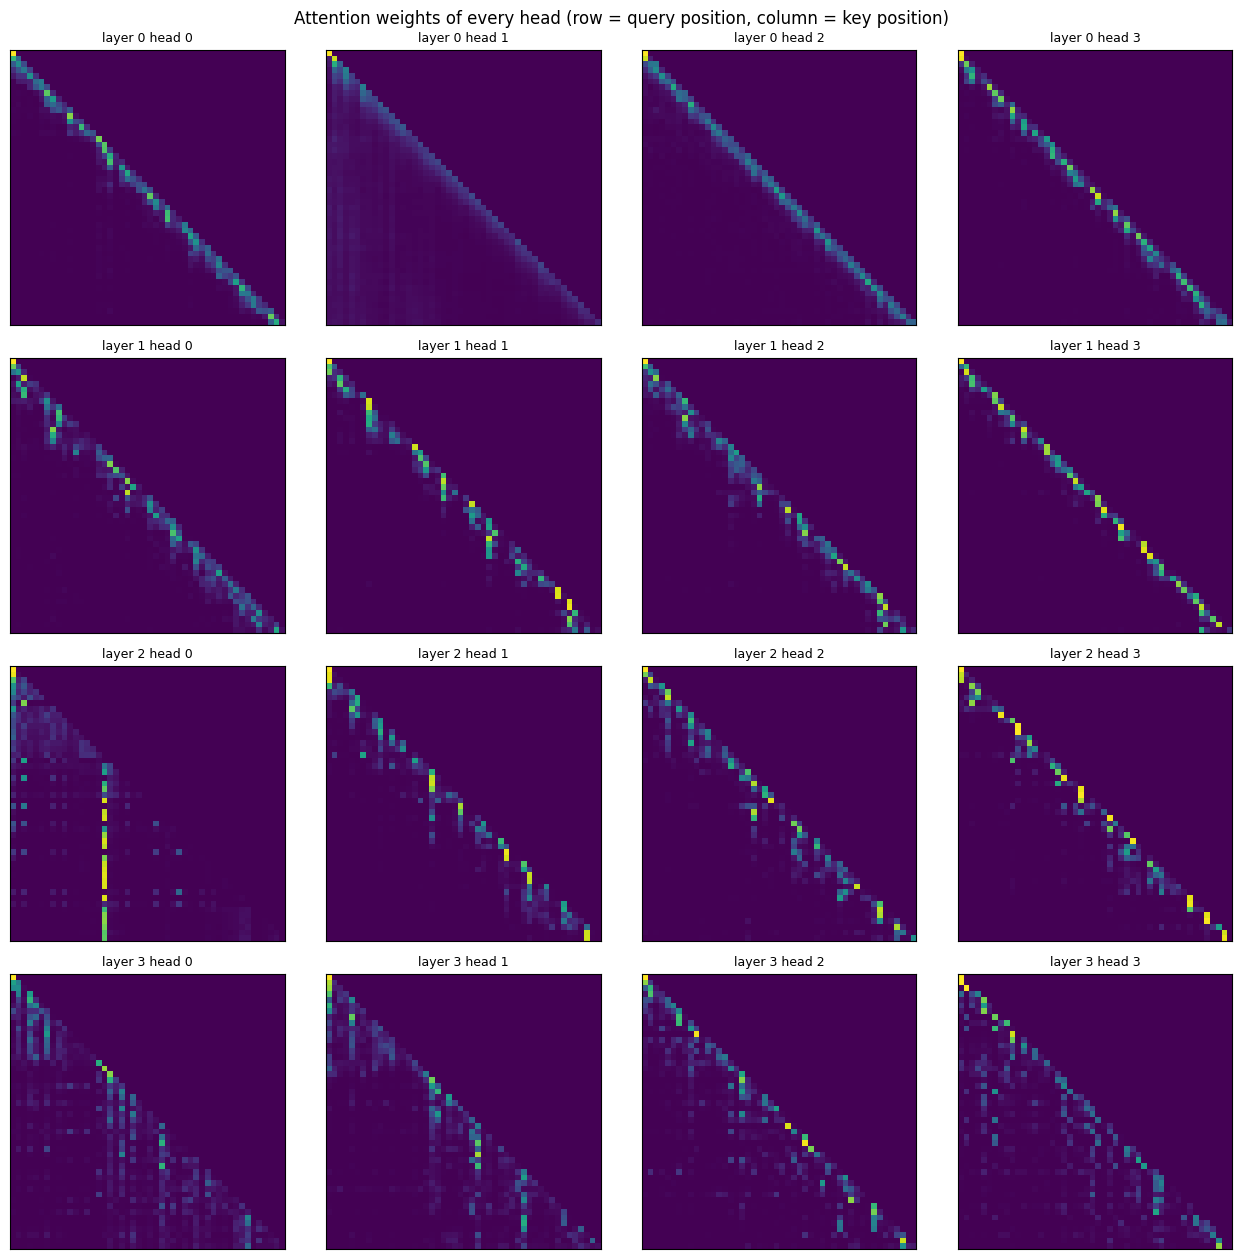

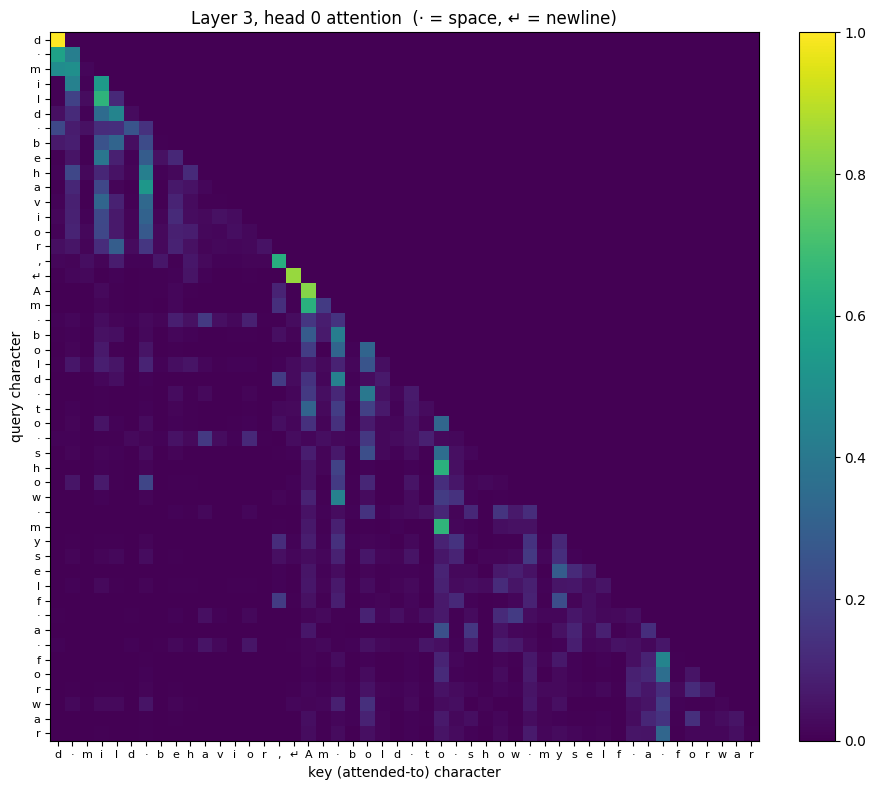


layer/head     prev-token attn   self attn
------------------------------------------
L0 H0                     0.417       0.230
L0 H1                     0.158       0.224
L0 H2                     0.394       0.227
L0 H3                     0.463       0.149
L1 H0                     0.321       0.129
L1 H1                     0.282       0.226
L1 H2                     0.327       0.216
L1 H3                     0.537       0.215
L2 H0                     0.066       0.056
L2 H1                     0.278       0.177
L2 H2                     0.350       0.193
L2 H3                     0.348       0.281
L3 H0                     0.122       0.143
L3 H1                     0.126       0.176
L3 H2                     0.310       0.181
L3 H3                     0.274       0.133


In [37]:
ATTN_SNIPPET = text[n_train + 500 : n_train + 500 + 48]
snippet_ids = torch.tensor([tokenizer.encode(ATTN_SNIPPET)], device=DEVICE)
print("snippet:", repr(ATTN_SNIPPET))

best_model.eval()
with torch.no_grad():
    _, _, attn_maps = best_model(snippet_ids, return_attn=True)   # list of (1, n_heads, T, T), one per layer

L, H = model_cfg.n_layers, model_cfg.n_heads

# --- view 1: all layers x heads ---
fig, axes = plt.subplots(L, H, figsize=(3.2 * H, 3.2 * L), squeeze=False)
for l in range(L):
    for h in range(H):
        axes[l, h].imshow(attn_maps[l][0, h].cpu(), cmap="viridis")
        axes[l, h].set_title(f"layer {l} head {h}", fontsize=9)
        axes[l, h].set_xticks([])
        axes[l, h].set_yticks([])
fig.suptitle("Attention weights of every head (row = query position, column = key position)")
plt.tight_layout()
plt.savefig("outputs/figures/fig7_attention_grid.png", dpi=150)
plt.show()

# --- view 2: one head with character labels ---
VIEW_LAYER, VIEW_HEAD = L - 1, 0
label = lambda c: "\u21b5" if c == "\n" else ("\u00b7" if c == " " else c)
chars = [label(c) for c in ATTN_SNIPPET]

plt.figure(figsize=(9, 8))
plt.imshow(attn_maps[VIEW_LAYER][0, VIEW_HEAD].cpu(), cmap="viridis")
plt.xticks(range(len(chars)), chars, fontsize=8)
plt.yticks(range(len(chars)), chars, fontsize=8)
plt.xlabel("key (attended-to) character")
plt.ylabel("query character")
plt.title(f"Layer {VIEW_LAYER}, head {VIEW_HEAD} attention  (\u00b7 = space, \u21b5 = newline)")
plt.colorbar(fraction=0.046)
plt.tight_layout()
plt.savefig("outputs/figures/fig7_attention_single_head.png", dpi=150)
plt.show()

# --- measurable head statistics ---
print(f"\n{'layer/head':<12}{'prev-token attn':>18}{'self attn':>12}")
print("-" * 42)
for l in range(L):
    for h in range(H):
        A = attn_maps[l][0, h].cpu()
        prev_tok = torch.diagonal(A, offset=-1).mean().item()
        self_attn = torch.diagonal(A, offset=0).mean().item()
        print(f"L{l} H{h:<9}{prev_tok:>18.3f}{self_attn:>12.3f}")

**What to look for (fill in with your own observations):** the strictly lower-triangular shape in every panel (causal mask at work); heads with a bright band just below the diagonal (attending to the previous character); heads that attend to newlines, punctuation, or the start of a word; whether early layers look more local and later layers more varied. Report only what the plots and the statistics table actually show.

### 5.9 Acceptance checks on the trained model (handout Section 16)

In [38]:
def test_best_checkpoint_reload_generates_identically():
    reloaded, tok2, _ = load_checkpoint(CKPT_BEST)
    prompt = torch.tensor([tokenizer.encode("ROMEO:")], device=DEVICE)
    a = best_model.generate(prompt, 60, temperature=0)
    b = reloaded.generate(prompt, 60, temperature=0)
    assert tok2.chars == tokenizer.chars
    assert torch.equal(a, b)


def test_trained_attention_never_looks_ahead():
    for l in range(L):
        A = attn_maps[l]                                   # (1, n_heads, T, T)
        future = torch.triu(A, diagonal=1)
        assert future.abs().max().item() < 1e-6, f"layer {l} attends to future positions"
        assert torch.allclose(A.sum(-1), torch.ones_like(A.sum(-1)), atol=1e-4)   # still valid distributions


def test_trained_model_ignores_future_tokens():
    x = snippet_ids.clone()
    x2 = x.clone()
    x2[:, -1] = (x2[:, -1] + 1) % tokenizer.vocab_size
    with torch.no_grad():
        l1, _ = best_model(x)
        l2, _ = best_model(x2)
    assert torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-4)


def test_trained_model_beats_uniform_baseline():
    assert final_val_loss < math.log(tokenizer.vocab_size) - 1.0


test_best_checkpoint_reload_generates_identically()
test_trained_attention_never_looks_ahead()
test_trained_model_ignores_future_tokens()
test_trained_model_beats_uniform_baseline()
print("ALL TESTS PASSED")

ALL TESTS PASSED


### 5.10 Save the run record

In [39]:
run_record = {
    "model_config": asdict(model_cfg),
    "train_config": asdict(train_cfg),
    "hardware": hardware,
    "results": results,
    "history": {k: v for k, v in hist.items() if k != "samples"},
}
with open("outputs/logs/minigpt_run.json", "w") as f:
    json.dump(run_record, f, indent=2)
print("saved -> outputs/logs/minigpt_run.json")

# Optional (Colab): copy the checkpoint to Google Drive so you can share a link in the README.
# from google.colab import drive
# drive.mount("/content/drive")
# !cp checkpoints/minigpt_best.pt /content/drive/MyDrive/minigpt_best.pt

saved -> outputs/logs/minigpt_run.json


**Milestone 5 checkpoint reached:** MiniGPT is trained on the full dataset; the parameter count, configuration, hardware, training time, final train/validation loss, six fixed-prompt samples, loss curves and attention inspection are all recorded, and the trained model passes the checkpoint-reload and causality acceptance checks. Next: Milestone 6 (ablation experiments, evaluation, CLI/API packaging).

---
## Milestone 6 — Evaluation, Ablations & Packaging

Covers: three controlled ablation experiments (depth, heads, context length) plus two optional ones (positional-encoding method, generation strategy), failure analysis with evidence, a standalone inference module, a **CLI**, a **FastAPI** service, and **Render** deployment files.

> **Prerequisite:** run Milestones 1-5 first (the ablations reuse the trained `best_model`, the tokenizer, `train()` and `full_split_loss`). The ablation block retrains 7 small models, so budget roughly 20-40 minutes on a Colab T4; lower `ABL_STEPS` if you need it faster.

### 6.1 Evaluation helpers — measuring generation quality

Loss alone does not tell you whether the text is any good, so we add two simple, reproducible text metrics (use them as *observations*; they are crude proxies, not a human judgement):

- **valid-word rate** — fraction of generated words that appear in the training corpus' word list. Low values mean the model is inventing or mangling words.
- **repetition rate** — `1 - (unique word 4-grams / total word 4-grams)`. High values mean the text loops.

Each metric is computed on the *continuation only* (the prompt is excluded) with a fixed seed.

In [40]:
import gc
import re
import shutil
import subprocess
import sys
from collections import Counter

import pandas as pd

TRAIN_WORDS = set(re.findall(r"[a-z']+", text[:n_train].lower()))
WORD_RE = re.compile(r"[A-Za-z']+")


def valid_word_rate(generated):
    words = [w.lower() for w in WORD_RE.findall(generated)]
    words = words[1:-1] if len(words) > 2 else words        # first/last word may be cut off
    if not words:
        return float("nan")
    return sum(w in TRAIN_WORDS for w in words) / len(words)


def repetition_rate(generated, n=4):
    words = WORD_RE.findall(generated.lower())
    grams = [tuple(words[i : i + n]) for i in range(len(words) - n + 1)]
    if not grams:
        return float("nan")
    return 1.0 - len(set(grams)) / len(grams)


def sample_continuation(model, prompt, max_new_tokens, temperature=0.8, top_k=None, seed=SEED):
    """Generate and return ONLY the continuation (prompt removed), reproducibly."""
    set_seed(seed)
    full = generate_text(model, tokenizer, prompt, max_new_tokens=max_new_tokens,
                         temperature=temperature, top_k=top_k)
    prompt_len = len(tokenizer.encode(prompt, errors="skip")) or 1
    return full[prompt_len:]


def generation_quality(model, prompts, n_tokens=400, temperature=0.8, top_k=None):
    conts = [sample_continuation(model, p, n_tokens, temperature, top_k) for p in prompts]
    return {
        "valid_word_rate": float(np.nanmean([valid_word_rate(c) for c in conts])),
        "repetition_rate": float(np.nanmean([repetition_rate(c) for c in conts])),
        "sample": conts[0],
    }

### 6.2 Ablation harness

One function trains a fresh model for a given configuration and returns a results row. To keep each experiment **controlled**:

- Everything not under test is identical to the baseline (`n_layers=4`, `n_heads=4`, `context_length=128`, `d_model=256`, dropout 0.1, same optimiser/schedule, same seed).
- Every run gets the **same number of steps** (`ABL_STEPS`) and the **same tokens per step** (`TOKENS_PER_STEP = 64 x 128`): for the context-length experiment the batch size is adjusted (`batch = 8192 // context_length`) so a 64-token model and a 256-token model see the same amount of text.
- The baseline is trained **once** and shared by all three experiments.
- Final losses use the deterministic full-split evaluation from Milestone 5. Reported training time includes the (small) periodic validation passes.

Note the baseline here is trained for fewer steps than the Milestone 5 model, so its numbers will be a bit worse than the M5 results; that is expected and does not affect the comparison.

In [41]:
ABL_STEPS = 1500                     # lower this if Colab time is tight
TOKENS_PER_STEP = 64 * 128           # held constant across all runs
ABL_BASE = dict(context_length=128, d_model=256, n_heads=4, n_layers=4, dropout=0.1)
ABL_PROMPTS = FIXED_PROMPTS[:3]


class LearnedPositionalEncoding(nn.Module):
    """Optional-experiment alternative to the sinusoidal encoding: a trainable table of position vectors."""

    def __init__(self, d_model, max_len):
        super().__init__()
        self.emb = nn.Embedding(max_len, d_model)
        nn.init.normal_(self.emb.weight, mean=0.0, std=0.02)

    def forward(self, x):
        T = x.shape[1]
        return x + self.emb(torch.arange(T, device=x.device)).unsqueeze(0)


class GPTLearnedPos(GPT):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.pos_enc = LearnedPositionalEncoding(cfg.d_model, cfg.context_length)


def run_experiment(label, overrides=None, position="sinusoidal", steps=ABL_STEPS):
    cfg = GPTConfig(vocab_size=tokenizer.vocab_size, **{**ABL_BASE, **(overrides or {})})
    batch_size = TOKENS_PER_STEP // cfg.context_length
    tcfg = TrainConfig(max_steps=steps, batch_size=batch_size, lr=6e-4, min_lr=6e-5, warmup_steps=100,
                       weight_decay=0.1, grad_clip=1.0, eval_interval=250, eval_iters=20,
                       log_interval=50, eval_at_start=False, seed=SEED)

    set_seed(SEED)
    m = (GPTLearnedPos if position == "learned" else GPT)(cfg).to(DEVICE)
    tr_ds = CharDataset(train_ids, cfg.context_length)
    va_ds = CharDataset(val_ids, cfg.context_length)
    n_par = count_parameters(m)
    print(f"=== {label} | {position} positions | params {n_par:,} | batch {batch_size} x ctx {cfg.context_length} ===")

    h = train(m, lambda: tr_ds.get_batch(batch_size), lambda: va_ds.get_batch(batch_size),
              tcfg, tokenizer=None, verbose=False)
    val_loss = full_split_loss(m, val_ids, cfg.context_length)
    train_loss = full_split_loss(m, train_ids, cfg.context_length)
    q = generation_quality(m, ABL_PROMPTS)

    row = {
        "setting": label,
        "params": n_par,
        "batch_x_ctx": f"{batch_size}x{cfg.context_length}",
        "val_loss": round(val_loss, 4),
        "val_ppl": round(math.exp(val_loss), 3),
        "train_loss": round(train_loss, 4),
        "gap": round(val_loss - train_loss, 4),
        "train_time_s": round(h["train_time_s"], 1),
        "tokens_per_s": round(h["tokens_per_s"]),
        "peak_mem_mb": round(h["peak_mem_mb"], 1) if h["peak_mem_mb"] is not None else None,
        "valid_word_rate": round(q["valid_word_rate"], 4),
        "repetition_rate": round(q["repetition_rate"], 4),
        "sample": q["sample"],
    }
    print(f"    val_loss {row['val_loss']} | time {row['train_time_s']}s | valid-word rate {row['valid_word_rate']}")

    del m
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return row, h


run_cache = {}


def get_run(label, overrides, position="sinusoidal"):
    key = (tuple(sorted((overrides or {}).items())), position)
    if key not in run_cache:
        run_cache[key] = run_experiment(label, overrides, position)
    return run_cache[key]

### 6.3 Run the three required experiments

| Experiment | Values | Measured |
|---|---|---|
| Depth | 2 / 4 / 6 blocks | validation loss, parameter count, training time |
| Heads | 2 / 4 / 8 heads | validation loss, generation quality |
| Context length | 64 / 128 / 256 | validation loss, memory, throughput |

In [42]:
EXPERIMENTS = {
    "Depth (n_layers)":     [("2", {"n_layers": 2}), ("4", {}), ("6", {"n_layers": 6})],
    "Heads (n_heads)":      [("2", {"n_heads": 2}),  ("4", {}), ("8", {"n_heads": 8})],
    "Context length":       [("64", {"context_length": 64}), ("128", {}), ("256", {"context_length": 256})],
}

rows = []
for exp_name, settings in EXPERIMENTS.items():
    for label, overrides in settings:
        row, _ = get_run(label, overrides)
        r = dict(row)
        r["experiment"] = exp_name
        r["baseline"] = (overrides == {})
        rows.append(r)

cols = ["experiment", "setting", "baseline", "params", "batch_x_ctx", "val_loss", "val_ppl", "train_loss",
        "gap", "train_time_s", "tokens_per_s", "peak_mem_mb", "valid_word_rate", "repetition_rate"]
ablation_df = pd.DataFrame(rows)
ablation_samples = {(r["experiment"], r["setting"]): r["sample"] for r in rows}

print("\n=== ABLATION RESULTS (Figure 9 table) ===")
print(ablation_df[cols].to_string(index=False))
ablation_df[cols].to_csv("outputs/logs/ablation_results.csv", index=False)
print("\nsaved -> outputs/logs/ablation_results.csv")

=== 2 | sinusoidal positions | params 1,611,264 | batch 64 x ctx 128 ===
    val_loss 1.7646 | time 58.5s | valid-word rate 0.8528
=== 4 | sinusoidal positions | params 3,188,736 | batch 64 x ctx 128 ===
    val_loss 1.6932 | time 111.4s | valid-word rate 0.8896
=== 6 | sinusoidal positions | params 4,766,208 | batch 64 x ctx 128 ===
    val_loss 1.6513 | time 166.4s | valid-word rate 0.9001
=== 2 | sinusoidal positions | params 3,188,736 | batch 64 x ctx 128 ===
    val_loss 1.6969 | time 107.0s | valid-word rate 0.8507
=== 8 | sinusoidal positions | params 3,188,736 | batch 64 x ctx 128 ===
    val_loss 1.7011 | time 122.9s | valid-word rate 0.8634
=== 64 | sinusoidal positions | params 3,188,736 | batch 128 x ctx 64 ===
    val_loss 1.6754 | time 106.3s | valid-word rate 0.8809
=== 256 | sinusoidal positions | params 3,188,736 | batch 32 x ctx 256 ===
    val_loss 1.7411 | time 124.9s | valid-word rate 0.8161

=== ABLATION RESULTS (Figure 9 table) ===
      experiment setting  basel

### 6.4 Figure 9 evidence — ablation plots

Top row: final validation loss per setting (baseline in orange; the y-axis is **truncated** to make small differences visible, so read the printed values too). Bottom row: validation-loss curves during training for each setting.

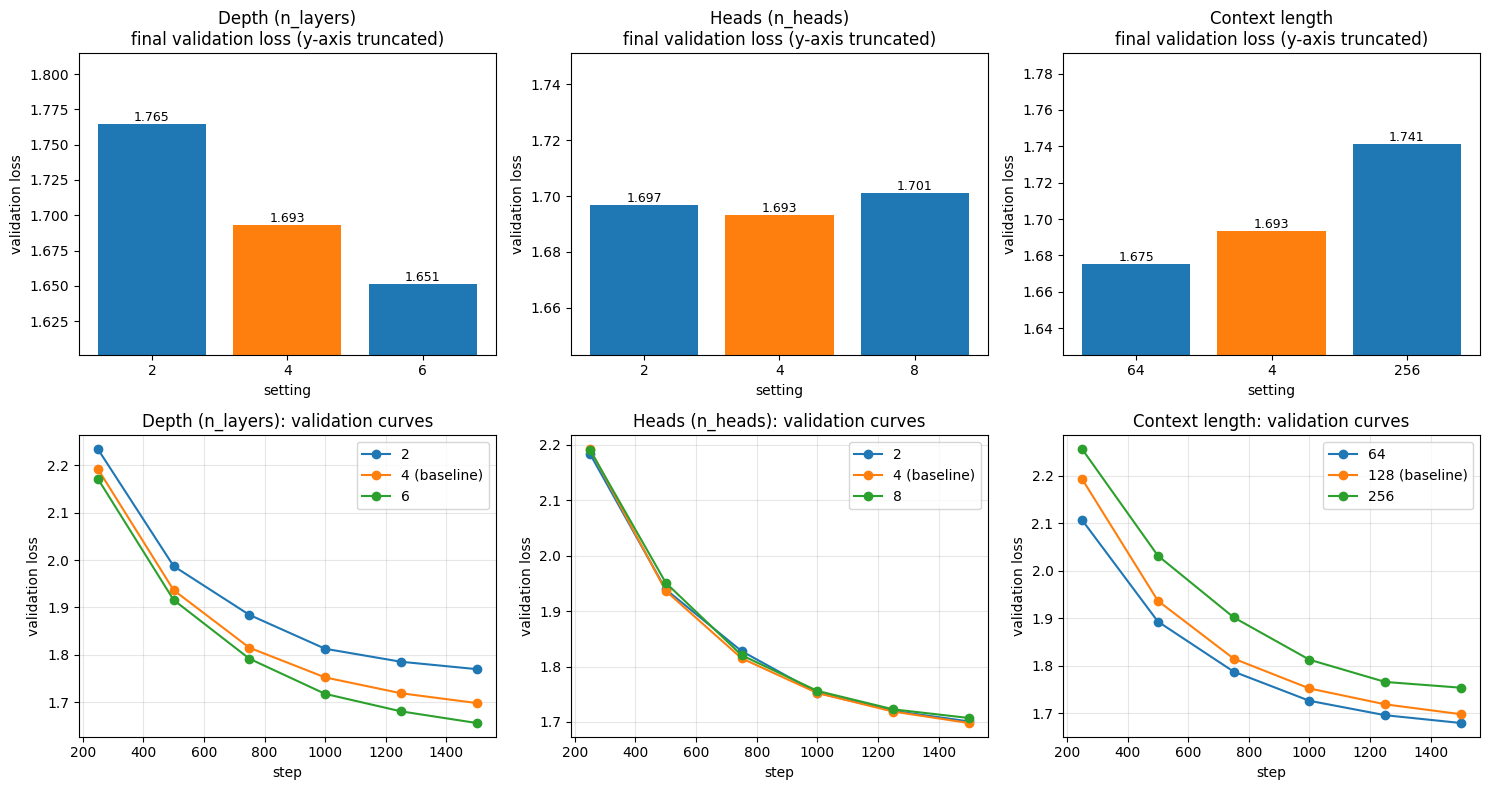

Generation sample per setting (first 250 chars, prompt 'ROMEO:'):

--- Depth (n_layers) = 2 ---

You before will and is not the dise abour to take
On the call and barthing our comment?

MEXENE:
And will my faces, which must of the of it heart made,
Your beg it endend in lattent drovers,
Here me nother transurel lind that the dead,
And the princ

--- Depth (n_layers) = 4 ---

You before will and in the tribers;
Thou be eyes grave the galands art that us him to be
they hoatess consul. What's will must of the county
Becommand dill, and if the necies all maid;
Good and him the woes was their in appaleted:
Thou have stand an

--- Depth (n_layers) = 6 ---

You before will a pursen, but be seem of bear.
Still not day talks and thy put of herty
From thou endrace my father, and I have with to the heart
male dill, and if else him. The set drovers, and
Will may go warm!

AUFIDIUS:
The husband him speak; an

--- Heads (n_heads) = 2 ---

Yet before with a purses, but
be senatory to take and my call

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, (exp_name, settings) in enumerate(EXPERIMENTS.items()):
    sub = ablation_df[ablation_df["experiment"] == exp_name]
    colors = ["tab:orange" if b else "tab:blue" for b in sub["baseline"]]

    ax = axes[0, j]
    ax.bar(sub["setting"].astype(str), sub["val_loss"], color=colors)
    lo, hi = sub["val_loss"].min(), sub["val_loss"].max()
    ax.set_ylim(lo - 0.05, hi + 0.05)
    for xi, v in enumerate(sub["val_loss"]):
        ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{exp_name}\nfinal validation loss (y-axis truncated)")
    ax.set_xlabel("setting")
    ax.set_ylabel("validation loss")

    ax2 = axes[1, j]
    for label, overrides in settings:
        _, h = get_run(label, overrides)
        ax2.plot(h["eval_step"], h["val_loss"], "o-", label=label + (" (baseline)" if overrides == {} else ""))
    ax2.set_xlabel("step")
    ax2.set_ylabel("validation loss")
    ax2.set_title(f"{exp_name}: validation curves")
    ax2.legend()
    ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("outputs/figures/fig9_ablation.png", dpi=150)
plt.show()

print("Generation sample per setting (first 250 chars, prompt 'ROMEO:'):")
for (exp, setting), s in ablation_samples.items():
    print(f"\n--- {exp} = {setting} ---")
    print(s[:250])

**How to write this up (observation vs. interpretation):**

- *Observation:* "Validation loss went from X (2 layers) to Y (4) to Z (6); parameters went from A to B to C; training time from ... to ...". Quote the table.
- *Interpretation:* only claim a mechanism (e.g. "more depth helps because ...") if something in the data supports it — e.g. the train/val **gap** column (is a bigger model just overfitting?), the validation curves (still improving or already flat?), the valid-word rate.

Caveats to state honestly: each setting is a **single seed** and a **short budget**, so differences of a few thousandths are within noise; for the context-length experiment the loss is averaged over positions inside a window, and a longer window gives later positions more context, so part of any improvement is "more context per token" rather than "better model"; the heads experiment holds `d_model` fixed, so more heads means a *smaller* `d_head` and (with this implementation) **the same parameter count**.

### 6.5 Optional experiments

**(a) Positional encoding: sinusoidal vs. learned** — one extra run with a trainable position table (`GPTLearnedPos`); compared against the shared baseline. Set `RUN_OPTIONAL_POSITION = False` to skip.

In [44]:
RUN_OPTIONAL_POSITION = True

if RUN_OPTIONAL_POSITION:
    base_row, base_hist = get_run("4", {})
    learned_row, learned_hist = get_run("learned", {}, position="learned")
    pos_df = pd.DataFrame([
        {**{k: v for k, v in base_row.items() if k != "sample"}, "setting": "sinusoidal (baseline)"},
        {**{k: v for k, v in learned_row.items() if k != "sample"}, "setting": "learned"},
    ])
    print(pos_df.to_string(index=False))
    pos_df.to_csv("outputs/logs/ablation_position.csv", index=False)
    print("\nlearned-position sample:\n", learned_row["sample"][:250])

=== learned | learned positions | params 3,221,504 | batch 64 x ctx 128 ===
    val_loss 1.7216 | time 111.9s | valid-word rate 0.8737
              setting  params batch_x_ctx  val_loss  val_ppl  train_loss    gap  train_time_s  tokens_per_s  peak_mem_mb  valid_word_rate  repetition_rate
sinusoidal (baseline) 3188736      64x128    1.6932    5.437      1.5017 0.1914         111.4        110309        797.9           0.8896              0.0
              learned 3221504      64x128    1.7216    5.593      1.5237 0.1979         111.9        109788        798.1           0.8737              0.0

learned-position sample:
 
You before with a worsen, but be seek of Aulieves?

QUEEN MARGARET:
What I have a beet?

MERCUTIO:
Why, now he fall to my must of the of the come mild,
Your beg in end not mild is the overy,
Here me now the was their and that these would by:
As that


**(b) Generation strategy: greedy vs. temperature vs. top-k** — no retraining; uses the trained `best_model` from Milestone 5 on five in-domain prompts, 500 new tokens each. Expect greedy decoding to repeat itself and high temperature to invent words; the two metrics put numbers on that.

In [45]:
STRATEGIES = [
    ("greedy (T=0)",       dict(temperature=0)),
    ("T=0.5",              dict(temperature=0.5)),
    ("T=0.8 (baseline)",   dict(temperature=0.8)),
    ("T=1.0",              dict(temperature=1.0)),
    ("T=1.3",              dict(temperature=1.3)),
    ("T=0.8, top-k=40",    dict(temperature=0.8, top_k=40)),
]

strategy_rows, strategy_text = [], {}
for name, kw in STRATEGIES:
    conts = [sample_continuation(best_model, p, 500, **kw) for p in FIXED_PROMPTS[:5]]
    strategy_text[name] = conts
    strategy_rows.append({
        "strategy": name,
        "valid_word_rate": round(float(np.nanmean([valid_word_rate(c) for c in conts])), 4),
        "repetition_rate": round(float(np.nanmean([repetition_rate(c) for c in conts])), 4),
    })

strategy_df = pd.DataFrame(strategy_rows)
print(strategy_df.to_string(index=False))
strategy_df.to_csv("outputs/logs/generation_strategy.csv", index=False)

for name in ["greedy (T=0)", "T=0.8 (baseline)", "T=1.3"]:
    print(f"\n--- {name} | prompt 'ROMEO:' (first 300 chars) ---")
    print(strategy_text[name][0][:300])

        strategy  valid_word_rate  repetition_rate
    greedy (T=0)           0.9825           0.3937
           T=0.5           0.9764           0.0000
T=0.8 (baseline)           0.9453           0.0000
           T=1.0           0.9317           0.0000
           T=1.3           0.7779           0.0000
 T=0.8, top-k=40           0.9453           0.0000

--- greedy (T=0) | prompt 'ROMEO:' (first 300 chars) ---

I am to the common of the country of the country.

KING RICHARD III:
The state of the court of the country,
That I will be the strange of the country's son,
And the state of the seat of the seat of the sea
The sease of the strange of the season of the state,
And she shall be the strange of the seat

--- T=0.8 (baseline) | prompt 'ROMEO:' (first 300 chars) ---

All thy bride will be on, but
being about to take and my cold and bardity;
Nurse, by that did how enjoy the confessary,
And he owes more in her to sleep;
Which in tell their ladies in the sea,
Which now thou art self and 

### 6.6 Failure analysis (at least two failure modes, with evidence)

Three failure modes to document, each backed by measurements from the cells below. Fill in the *likely cause* in your own words.

1. **Repetition loops under greedy decoding** — the argmax token is always chosen, so once the model enters a high-probability cycle it can never leave it.
2. **Invented / mangled words at higher temperature** — a character-level model has no word list; it composes words letter by letter, so flatter distributions produce plausible-looking non-words.
3. **Out-of-domain prompts and out-of-vocabulary characters** — the vocabulary is only the ~65 characters of Shakespeare (no digits, no most symbols), and the model has only ever seen one style of text.

In [46]:
# --- Failure mode 1: repetition under greedy decoding ---
greedy_text = strategy_text["greedy (T=0)"][0]
sampled_text = strategy_text["T=0.8 (baseline)"][0]
lines = [ln.strip() for ln in greedy_text.split("\n") if ln.strip()]
top_line, top_count = Counter(lines).most_common(1)[0]

print("FAILURE MODE 1 - greedy repetition")
print(f"  greedy   : repetition_rate = {repetition_rate(greedy_text):.3f}")
print(f"  T=0.8    : repetition_rate = {repetition_rate(sampled_text):.3f}")
print(f"  most repeated line in greedy output ({top_count}x): {top_line!r}")
print("  --- greedy sample (first 400 chars) ---")
print(greedy_text[:400])

# --- Failure mode 2: invented words ---
print("\nFAILURE MODE 2 - invented words")
for name in ["T=0.5", "T=1.0", "T=1.3"]:
    words = [w.lower() for c in strategy_text[name] for w in WORD_RE.findall(c)]
    bad = [w for w in words if w not in TRAIN_WORDS]
    print(f"  {name:<6}: {len(bad)}/{len(words)} words not in the training vocabulary "
          f"({100 * len(bad) / max(1, len(words)):.1f}%)")
words_hot = [w.lower() for c in strategy_text["T=1.3"] for w in WORD_RE.findall(c)]
print("  examples of invented words at T=1.3:", [w for w, _ in Counter(w for w in words_hot if w not in TRAIN_WORDS).most_common(12)])

# --- Failure mode 3: out-of-domain prompt / out-of-vocabulary characters ---
print("\nFAILURE MODE 3 - out-of-domain prompt and unsupported characters")
ood_prompt = "The future of AI in 2026: self-driving cars & GPUs"
dropped = sorted(set(ood_prompt) - set(tokenizer.chars))
print(f"  prompt sent        : {ood_prompt!r}")
print(f"  prompt the model sees: {tokenizer.decode(tokenizer.encode(ood_prompt, errors='skip'))!r}")
print(f"  characters dropped : {dropped}")
print("  --- continuation (first 300 chars) ---")
print(sample_continuation(best_model, ood_prompt, 300)[:300])

FAILURE MODE 1 - greedy repetition
  greedy   : repetition_rate = 0.320
  T=0.8    : repetition_rate = 0.000
  most repeated line in greedy output (2x): 'KING RICHARD III:'
  --- greedy sample (first 400 chars) ---

I am to the common of the country of the country.

KING RICHARD III:
The state of the court of the country,
That I will be the strange of the country's son,
And the state of the seat of the seat of the sea
The sease of the strange of the season of the state,
And she shall be the strange of the seat,
And the state of the seat of the seat of the sea
The sease of the strange of the seat of the state

FAILURE MODE 2 - invented words
  T=0.5 : 13/517 words not in the training vocabulary (2.5%)
  T=1.0 : 39/492 words not in the training vocabulary (7.9%)
  T=1.3 : 99/448 words not in the training vocabulary (22.1%)
  examples of invented words at T=1.3: ['somerry', 'overtage', 'lesing', "'coursey", 'aiss', 'furny', 'dill', 'senatore', 'cound', 'nybirty', 'smoock', 'treasts']

FAI

### 6.7 Final evaluation summary (fixed prompts + quantitative loss)

Combines the Milestone 5 loss/perplexity numbers with the text metrics over all six fixed prompts (temperature 0.8, 500 new tokens, fixed seed).

In [47]:
eval_rows = []
for p in FIXED_PROMPTS:
    c = sample_continuation(best_model, p, 500, temperature=0.8)
    eval_rows.append({"prompt": repr(p)[:42],
                      "valid_word_rate": round(valid_word_rate(c), 4),
                      "repetition_rate": round(repetition_rate(c), 4)})
eval_df = pd.DataFrame(eval_rows)
print(eval_df.to_string(index=False))

print(f"\nmean valid-word rate : {eval_df['valid_word_rate'].mean():.4f}")
print(f"mean repetition rate : {eval_df['repetition_rate'].mean():.4f}")
print(f"validation loss      : {final_val_loss:.4f} | perplexity {math.exp(final_val_loss):.3f} | {final_val_loss / math.log(2):.3f} bits/char")
print(f"training loss        : {final_train_loss:.4f} | perplexity {math.exp(final_train_loss):.3f}")
eval_df.to_csv("outputs/logs/final_eval_prompts.csv", index=False)

                                 prompt  valid_word_rate  repetition_rate
                               'ROMEO:'           0.9510              0.0
                     'First Citizen:\n'           0.9604              0.0
                  'To be, or not to be'           0.9596              0.0
                             'The king'           0.9091              0.0
                            'JULIET:\n'           0.9462              0.0
'The future of artificial intelligence'           0.9400              0.0

mean valid-word rate : 0.9444
mean repetition rate : 0.0000
validation loss      : 1.5382 | perplexity 4.656 | 2.219 bits/char
training loss        : 1.3020 | perplexity 3.677


---
### 6.8 Packaging — standalone module, CLI, FastAPI, Render

The notebook writes a small deployable package into `deploy/`:

```
deploy/
  minigpt.py          # standalone model + tokenizer + loader (inference only, no training code)
  generate.py         # command-line interface
  api.py              # FastAPI service  (GET /health, POST /generate)
  requirements.txt    # CPU-only torch + fastapi + uvicorn
  render.yaml         # Render blueprint
  README.md           # setup / commands / limitations (fill in the TODOs)
  minigpt_best.pt     # the trained checkpoint (copied from checkpoints/)
```

`minigpt.py` re-states the architecture so the service does not need the notebook. A test below proves it produces **identical output** to the notebook model, so the two cannot silently drift apart.

In [48]:
os.makedirs("deploy", exist_ok=True)
print("created deploy/")

created deploy/


In [49]:
%%writefile deploy/minigpt.py
"""Standalone MiniGPT inference module (model + character tokenizer + checkpoint loader).

Mirrors the architecture trained in the notebook: token embedding + sinusoidal positions,
N pre-norm causal Transformer blocks, final LayerNorm, linear LM head.
"""
import math
from dataclasses import dataclass

import torch
import torch.nn as nn
import torch.nn.functional as F


def build_causal_mask(T, device=None):
    """(T, T) boolean mask, True where the key position is in the future of the query position."""
    return torch.triu(torch.ones(T, T, dtype=torch.bool, device=device), diagonal=1)


def scaled_dot_product_attention(Q, K, V, causal=True):
    d_k = Q.shape[-1]
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)
    if causal:
        T_q, T_k = scores.shape[-2], scores.shape[-1]
        mask = build_causal_mask(max(T_q, T_k), device=scores.device)[:T_q, :T_k]
        scores = scores.masked_fill(mask, float("-inf"))
    weights = F.softmax(scores, dim=-1)
    return weights @ V, weights


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads, causal=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.causal = causal
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model, bias=False)

    def split_heads(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

    def merge_heads(self, x):
        B, H, T, D = x.shape
        return x.transpose(1, 2).contiguous().view(B, T, H * D)

    def forward(self, x):
        Q, K, V = self.split_heads(self.W_q(x)), self.split_heads(self.W_k(x)), self.split_heads(self.W_v(x))
        out, attn = scaled_dot_product_attention(Q, K, V, causal=self.causal)
        return self.W_o(self.merge_heads(out)), attn


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, : x.shape[1], :]


class FeedForward(nn.Module):
    def __init__(self, d_model, ffn_dim, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_dim), nn.GELU(), nn.Linear(ffn_dim, d_model), nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, ffn_dim, dropout=0.0, causal=True):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadAttention(d_model, n_heads, causal=causal)
        self.drop1 = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, ffn_dim, dropout=dropout)
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x):
        attn_out, attn = self.attn(self.ln1(x))
        x = x + self.drop1(attn_out)
        x = x + self.drop2(self.ffn(self.ln2(x)))
        return x, attn


@dataclass
class GPTConfig:
    vocab_size: int = 65
    context_length: int = 128
    d_model: int = 256
    n_heads: int = 4
    n_layers: int = 4
    ffn_dim: int = None
    dropout: float = 0.1
    tie_weights: bool = False

    def __post_init__(self):
        if self.ffn_dim is None:
            self.ffn_dim = 4 * self.d_model


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.pos_enc = SinusoidalPositionalEncoding(cfg.d_model, max_len=cfg.context_length)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList(
            [TransformerBlock(cfg.d_model, cfg.n_heads, cfg.ffn_dim, cfg.dropout) for _ in range(cfg.n_layers)]
        )
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx):
        assert idx.shape[1] <= self.cfg.context_length
        x = self.tok_emb(idx) * math.sqrt(self.cfg.d_model)
        x = self.drop(self.pos_enc(x))
        for block in self.blocks:
            x, _ = block(x)
        return self.lm_head(self.ln_f(x))

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=None):
        was_training = self.training
        self.eval()
        for _ in range(max_new_tokens):
            logits = self(idx[:, -self.cfg.context_length:])[:, -1, :]
            if temperature == 0:
                next_id = torch.argmax(logits, dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k is not None:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, [-1]]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                next_id = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        self.train(was_training)
        return idx


class CharTokenizer:
    def __init__(self, chars):
        self.chars = list(chars)
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for i, c in enumerate(self.chars)}

    @property
    def vocab_size(self):
        return len(self.chars)

    def encode(self, s, errors="raise"):
        ids = []
        for c in s:
            if c in self.stoi:
                ids.append(self.stoi[c])
            elif errors != "skip":
                raise KeyError(f"character {c!r} is not in the vocabulary")
        return ids

    def decode(self, ids):
        return "".join(self.itos[int(i)] for i in ids)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def load_model(path, device="cpu"):
    """Load a checkpoint written by the notebook. Returns (model, tokenizer, checkpoint_dict)."""
    device = torch.device(device)
    ckpt = torch.load(path, map_location=device)
    model = GPT(GPTConfig(**ckpt["gpt_config"])).to(device)
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    return model, CharTokenizer(ckpt["tokenizer_chars"]), ckpt


def generate_text(model, tokenizer, prompt, max_new_tokens=200, temperature=0.8, top_k=None):
    """Prompt string in -> prompt + continuation string out."""
    device = next(model.parameters()).device
    prompt_ids = tokenizer.encode(prompt, errors="skip") or tokenizer.encode("\n")
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens, temperature=temperature, top_k=top_k)
    return tokenizer.decode(out[0].tolist())


Writing deploy/minigpt.py


In [50]:
%%writefile deploy/generate.py
"""Command-line interface for MiniGPT.

Example:
    python generate.py --prompt "ROMEO:" --max-new-tokens 200 --temperature 0.8
"""
import argparse
import os
import sys

import torch

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from minigpt import count_parameters, generate_text, load_model  # noqa: E402

HERE = os.path.dirname(os.path.abspath(__file__))


def main():
    p = argparse.ArgumentParser(description="Generate text with the from-scratch MiniGPT model.")
    p.add_argument("--prompt", type=str, default="ROMEO:")
    p.add_argument("--max-new-tokens", type=int, default=200)
    p.add_argument("--temperature", type=float, default=0.8, help="0 = greedy decoding")
    p.add_argument("--top-k", type=int, default=None)
    p.add_argument("--seed", type=int, default=1337)
    p.add_argument("--checkpoint", type=str, default=os.path.join(HERE, "minigpt_best.pt"))
    p.add_argument("--device", type=str, default="cuda" if torch.cuda.is_available() else "cpu")
    args = p.parse_args()

    torch.manual_seed(args.seed)
    model, tokenizer, _ = load_model(args.checkpoint, device=args.device)
    out = generate_text(model, tokenizer, args.prompt, args.max_new_tokens, args.temperature, args.top_k)

    print(f"Prompt: {args.prompt}")
    print("Generated:")
    print(out)
    print("---")
    print(f"model parameters: {count_parameters(model) / 1e6:.2f}M")
    print(f"context length: {model.cfg.context_length}")
    print(f"temperature: {args.temperature}")
    print(f"top_k: {args.top_k}")
    print(f"seed: {args.seed}")


if __name__ == "__main__":
    main()


Writing deploy/generate.py


In [51]:
%%writefile deploy/api.py
"""FastAPI service for MiniGPT.

Run locally:   uvicorn api:app --host 0.0.0.0 --port 8000
Endpoints:     GET /  |  GET /health  |  POST /generate
Environment:   CHECKPOINT_PATH (default: minigpt_best.pt next to this file)
               CHECKPOINT_URL  (optional: downloaded at startup if the checkpoint file is missing)
"""
import os
import threading
import time
import urllib.request
from contextlib import asynccontextmanager
from typing import Optional

import torch
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from minigpt import count_parameters, generate_text, load_model

HERE = os.path.dirname(os.path.abspath(__file__))
CHECKPOINT_PATH = os.environ.get("CHECKPOINT_PATH", os.path.join(HERE, "minigpt_best.pt"))
CHECKPOINT_URL = os.environ.get("CHECKPOINT_URL")

STATE = {}
LOCK = threading.Lock()


def _ensure_checkpoint():
    if os.path.exists(CHECKPOINT_PATH):
        return
    if not CHECKPOINT_URL:
        raise RuntimeError(f"checkpoint not found at {CHECKPOINT_PATH} and CHECKPOINT_URL is not set")
    urllib.request.urlretrieve(CHECKPOINT_URL, CHECKPOINT_PATH)


@asynccontextmanager
async def lifespan(app: FastAPI):
    _ensure_checkpoint()
    model, tokenizer, _ = load_model(CHECKPOINT_PATH, device="cpu")
    STATE["model"] = model
    STATE["tokenizer"] = tokenizer
    yield
    STATE.clear()


app = FastAPI(title="MiniGPT API", version="1.0", lifespan=lifespan)


class GenerateRequest(BaseModel):
    prompt: str = Field("ROMEO:", max_length=500)
    max_new_tokens: int = Field(200, ge=1, le=500)
    temperature: float = Field(0.8, ge=0.0, le=2.0, description="0 = greedy decoding")
    top_k: Optional[int] = Field(None, ge=1, le=100)
    seed: Optional[int] = Field(None, description="set for reproducible output")


@app.get("/")
def root():
    if "model" not in STATE:
        raise HTTPException(status_code=503, detail="model not loaded")
    model = STATE["model"]
    return {
        "name": "MiniGPT (from-scratch Transformer, character-level, Tiny Shakespeare)",
        "parameters": count_parameters(model),
        "context_length": model.cfg.context_length,
        "vocab_size": model.cfg.vocab_size,
        "usage": "POST /generate with JSON {prompt, max_new_tokens, temperature, top_k, seed}",
    }


@app.get("/health")
def health():
    return {"status": "ok", "model_loaded": "model" in STATE}


@app.post("/generate")
def generate(req: GenerateRequest):
    if "model" not in STATE:
        raise HTTPException(status_code=503, detail="model not loaded")
    model, tokenizer = STATE["model"], STATE["tokenizer"]
    ignored = sorted(set(req.prompt) - set(tokenizer.chars))
    start = time.time()
    with LOCK:
        if req.seed is not None:
            torch.manual_seed(req.seed)
        generated = generate_text(model, tokenizer, req.prompt, req.max_new_tokens, req.temperature, req.top_k)
    return {
        "prompt": req.prompt,
        "generated": generated,
        "ignored_characters": ignored,
        "parameters": count_parameters(model),
        "context_length": model.cfg.context_length,
        "temperature": req.temperature,
        "top_k": req.top_k,
        "seconds": round(time.time() - start, 3),
    }


Writing deploy/api.py


In [52]:
%%writefile deploy/requirements.txt
--extra-index-url https://download.pytorch.org/whl/cpu
torch
fastapi
uvicorn


Writing deploy/requirements.txt


In [53]:
%%writefile deploy/render.yaml
# Render Blueprint. Push this repository to GitHub, then in Render: New > Blueprint > select the repo.
# (Or create a Web Service manually with the same build/start commands and root directory "deploy".)
services:
  - type: web
    name: minigpt-api
    runtime: python
    plan: free
    rootDir: deploy
    buildCommand: pip install -r requirements.txt
    startCommand: uvicorn api:app --host 0.0.0.0 --port $PORT
    healthCheckPath: /health
    envVars:
      - key: PYTHON_VERSION
        value: 3.11.9
      # Only needed if you do NOT commit minigpt_best.pt (e.g. host it on a GitHub release / Drive direct link):
      - key: CHECKPOINT_URL
        sync: false


Writing deploy/render.yaml


In [54]:
%%writefile deploy/README.md
# MiniGPT - a Transformer language model built from scratch

A small GPT-style, character-level causal language model (attention, multi-head attention, sinusoidal
positions, residual blocks, LayerNorm, FFN, LM head) implemented in PyTorch **without any pretrained model**,
trained on Tiny Shakespeare.

> TODO: add team names, course, and links (Colab notebook, Medium report, demo video, live API).

## Repository layout
| Path | What it is |
|---|---|
| `AI_Engineering_Transformer_GPT.ipynb` | Full notebook: attention, multi-head, positions, blocks, training, ablations, packaging |
| `deploy/minigpt.py` | Standalone model + tokenizer + checkpoint loader (inference only) |
| `deploy/generate.py` | Command-line interface |
| `deploy/api.py` | FastAPI service |
| `deploy/minigpt_best.pt` | Trained checkpoint (TODO: ~13 MB; or host it and set `CHECKPOINT_URL`) |
| `outputs/figures`, `outputs/logs`, `outputs/samples` | Figures, metrics/ablation CSVs, generated samples |

## Dataset
Tiny Shakespeare (~1.1 MB, ~40k lines), the corpus from Karpathy's `char-rnn`
(https://github.com/karpathy/char-rnn), also on Hugging Face as "tiny_shakespeare". Downloaded automatically by the notebook.
Character-level tokenizer, 65-character vocabulary, no special tokens. 90/10 contiguous train/validation split.

## Setup
```bash
pip install -r deploy/requirements.txt
```

## Training (reproduce the checkpoint)
Open the notebook in Google Colab (GPU runtime) and run Milestones 1-5 top to bottom.
Config used: d_model=256, n_heads=4, n_layers=4, ffn_dim=1024, context=128, dropout=0.1, AdamW, lr 6e-4 (cosine, 200 warm-up), batch 64, 3000 steps.
TODO: paste final parameter count, hardware, wall-clock time, train/val loss.

## Inference - CLI
```bash
python deploy/generate.py --prompt "ROMEO:" --max-new-tokens 200 --temperature 0.8
```
Expected output: the prompt, a Shakespeare-style continuation, then parameter count, context length, and temperature.
Use `--temperature 0` for greedy decoding, `--top-k 40` for top-k sampling, `--seed` for reproducibility.

## Inference - REST API
```bash
cd deploy
uvicorn api:app --host 0.0.0.0 --port 8000
curl -X POST http://localhost:8000/generate -H "Content-Type: application/json" \
  -d '{"prompt": "ROMEO:", "max_new_tokens": 100, "temperature": 0.8, "seed": 1}'
```
Interactive docs at `/docs`. Health check at `/health`.

## Deploy on Render
1. Push the repository (including `deploy/minigpt_best.pt`, or set `CHECKPOINT_URL`) to GitHub.
2. Render dashboard > New > Blueprint > pick the repo (uses `deploy/render.yaml`), or create a Web Service with
   root directory `deploy`, build `pip install -r requirements.txt`, start `uvicorn api:app --host 0.0.0.0 --port $PORT`.
3. Live URL: TODO. Note: the free tier sleeps when idle, so the first request after a pause is slow.

## Tests
The notebook runs every `test_*` function (attention shapes, causal masking, target shifting, end-to-end causality,
checkpoint reload, exported-module equivalence) and a tiny-overfit gate.

## Known limitations
- Character-level, 65-character vocabulary: digits and most symbols are silently dropped from prompts.
- Trained on ~1 MB of one author; output imitates the style but is not factual or semantically coherent over long spans.
- Greedy decoding loops; high temperature invents words (see the failure analysis in the report).
- Context window is 128 characters; earlier text is forgotten during longer generations.

## Sources
TODO: cite the Tiny Shakespeare source, "Attention Is All You Need" (Vaswani et al., 2017), and any tutorial code you adapted.


Writing deploy/README.md


#### Copy the checkpoint into the package and verify it

Three checks, matching the handout's acceptance tests: (1) the exported standalone module reproduces the notebook model's output **exactly** (greedy), (2) the CLI runs from a fresh process and prints the required fields (Figure 10), (3) the FastAPI service starts and answers a real HTTP request (Figure 10).

In [55]:
shutil.copy(CKPT_BEST, "deploy/minigpt_best.pt")
size_mb = os.path.getsize("deploy/minigpt_best.pt") / 2**20
print(f"copied checkpoint -> deploy/minigpt_best.pt ({size_mb:.1f} MB)")

import importlib
if "deploy" not in sys.path:
    sys.path.insert(0, "deploy")
import minigpt as pkg
importlib.reload(pkg)


def test_exported_module_matches_notebook_model():
    pkg_model, pkg_tok, _ = pkg.load_model("deploy/minigpt_best.pt", device=str(DEVICE))
    assert pkg_tok.chars == tokenizer.chars
    assert pkg.count_parameters(pkg_model) == count_parameters(best_model)
    prompt_ids = torch.tensor([tokenizer.encode("ROMEO:")], device=DEVICE)
    a = best_model.generate(prompt_ids, 120, temperature=0)
    b = pkg_model.generate(prompt_ids, 120, temperature=0)
    assert torch.equal(a, b), "exported module output differs from the notebook model"


test_exported_module_matches_notebook_model()
print("exported module == notebook model (identical greedy output): OK")

copied checkpoint -> deploy/minigpt_best.pt (12.3 MB)
exported module == notebook model (identical greedy output): OK


In [56]:
# Figure 10a - CLI inference, run in a FRESH process
cmd = [sys.executable, "deploy/generate.py",
       "--prompt", "The future of artificial intelligence",
       "--max-new-tokens", "80", "--temperature", "0.8"]
print("$ " + " ".join(cmd) + "\n")
res = subprocess.run(cmd, capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print("STDERR:", res.stderr)
assert res.returncode == 0

$ /usr/bin/python3 deploy/generate.py --prompt The future of artificial intelligence --max-new-tokens 80 --temperature 0.8

Prompt: The future of artificial intelligence
Generated:
The future of artificial intelligence?

CLARENCE:
I will be received a senator, and all the streetche
he would he sha
---
model parameters: 3.19M
context length: 128
temperature: 0.8
top_k: None
seed: 1337



In [57]:
# Figure 10b - REST API: start the real server, call it over HTTP, shut it down
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "fastapi", "uvicorn", "requests"], check=True)
import requests

server_log = open("outputs/logs/uvicorn.log", "w")
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "api:app", "--host", "127.0.0.1", "--port", "8000"],
                          cwd="deploy", stdout=server_log, stderr=subprocess.STDOUT)
try:
    for _ in range(90):                                    # wait until the model has loaded
        try:
            if requests.get("http://127.0.0.1:8000/health", timeout=1).json().get("model_loaded"):
                break
        except Exception:
            pass
        time.sleep(1)

    print("GET /health ->", requests.get("http://127.0.0.1:8000/health").json())
    print("GET /       ->", requests.get("http://127.0.0.1:8000/").json())

    payload = {"prompt": "ROMEO:", "max_new_tokens": 100, "temperature": 0.8, "seed": 1}
    print("\nPOST /generate", payload)
    r = requests.post("http://127.0.0.1:8000/generate", json=payload)
    print("status:", r.status_code)
    body = r.json()
    print(body["generated"])
    print({k: v for k, v in body.items() if k not in ("generated", "prompt")})

    bad = requests.post("http://127.0.0.1:8000/generate", json={"prompt": "x", "temperature": 99})
    print("\ninvalid request (temperature=99) ->", bad.status_code, "(validation works)")
    assert r.status_code == 200 and bad.status_code == 422
finally:
    server.terminate()
    server.wait(timeout=10)
    server_log.close()
print("\nserver stopped")

GET /health -> {'status': 'ok', 'model_loaded': True}
GET /       -> {'name': 'MiniGPT (from-scratch Transformer, character-level, Tiny Shakespeare)', 'parameters': 3188736, 'context_length': 128, 'vocab_size': 65, 'usage': 'POST /generate with JSON {prompt, max_new_tokens, temperature, top_k, seed}'}

POST /generate {'prompt': 'ROMEO:', 'max_new_tokens': 100, 'temperature': 0.8, 'seed': 1}
status: 200
ROMEO:
Camillo;
Men me ungly that may be my shame with a virtue,
And he more a mistain of the heavy west:

{'ignored_characters': [], 'parameters': 3188736, 'context_length': 128, 'temperature': 0.8, 'top_k': None, 'seconds': 0.817}

invalid request (temperature=99) -> 422 (validation works)

server stopped


### 6.9 Run every test (handout acceptance checks)

Runs **all** `test_*` functions defined in this notebook (M1-M6) and prints a pass/fail summary. The tiny-overfit gate from Milestone 4 is an executed cell rather than a function, so confirm it printed `OVERFIT GATE PASSED`.

In [58]:
def run_all_tests():
    results = []
    for name, fn in sorted(globals().items()):
        if name.startswith("test_") and callable(fn):
            try:
                fn()
                results.append((name, "PASS", ""))
            except Exception as e:
                results.append((name, "FAIL", repr(e)[:120]))
    width = max(len(n) for n, _, _ in results)
    for name, status, err in results:
        print(f"{name:<{width}}  {status}  {err}")
    n_fail = sum(s == "FAIL" for _, s, _ in results)
    print(f"\n{len(results) - n_fail}/{len(results)} tests passed")
    return n_fail


assert run_all_tests() == 0, "some tests failed"

test_best_checkpoint_reload_generates_identically  PASS  
test_bidirectional_block_uses_future_tokens        PASS  
test_causal_block_ignores_future_tokens            PASS  
test_causal_mask_blocks_future                     PASS  
test_checkpoint_roundtrip                          PASS  
test_dataset_target_shift                          PASS  
test_explicit_mask_matches_causal_helper           PASS  
test_exported_module_matches_notebook_model        PASS  
test_generation_length_and_greedy_determinism      PASS  
test_gpt_forward_shapes_and_initial_loss           PASS  
test_gpt_is_causal_end_to_end                      PASS  
test_multihead_causal_mask_blocks_future           PASS  
test_multihead_requires_divisible_d_model          PASS  
test_multihead_shapes                              PASS  
test_output_and_weight_shapes                      PASS  
test_positional_encoding_shape_and_variation       PASS  
test_self_attention_module_shapes                  PASS  
test_tokenizer

### 6.10 Bundle the artifacts

Zips `deploy/`, `outputs/` (figures, logs, samples) and the checkpoint so you can download everything from Colab in one go and commit the right files to GitHub (do **not** commit credentials or the dataset if your instructor asks otherwise).

In [59]:
shutil.make_archive("minigpt_submission", "zip", root_dir=".", base_dir="deploy")
shutil.make_archive("minigpt_outputs", "zip", root_dir=".", base_dir="outputs")
print("created minigpt_submission.zip (deploy package) and minigpt_outputs.zip (figures, logs, samples)")

# In Colab you can download them with:
# from google.colab import files
# files.download("minigpt_submission.zip"); files.download("minigpt_outputs.zip")

created minigpt_submission.zip (deploy package) and minigpt_outputs.zip (figures, logs, samples)


In [60]:
print(os.path.abspath("minigpt_submission.zip"))

/content/minigpt_submission.zip


In [63]:
!du -sh /content/checkpoints
!du -sh /content/data
shutil.make_archive("minigpt_checkpoints", "zip", root_dir=".", base_dir="checkpoints")
shutil.make_archive("minigpt_data", "zip", root_dir=".", base_dir="data")

25M	/content/checkpoints
1.1M	/content/data


'/content/minigpt_data.zip'

In [2]:
from google.colab import files
import os

# Put all your zip file names here
zip_files = ['minigpt_submission.zip', 'minigpt_outputs.zip', 'minigpt_checkpoints.zip', 'minigpt_data.zip']

for file_name in zip_files:
    if os.path.exists(file_name):
        print(file_name)
        files.download(file_name)
    else:
        print(f"File not found in Colab: {file_name}")


minigpt_submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

minigpt_outputs.zip


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

minigpt_data.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Milestone 6 checkpoint reached.** Ablations (depth / heads / context, plus optional position and generation-strategy studies), failure analysis, a verified standalone module, CLI, FastAPI service, and Render deployment files are in place.

**What is still on you (not code):** push `deploy/`, the notebook and the outputs to a GitHub repo; deploy to Render and put the live URL in the README; write the hand-calculation section and the report/Medium article (use the figure checklist in Section 12 and the observation-vs-interpretation guidance above); record the 5-10 minute demo; and cite your sources.